# BÁO CÁO BÀI THỰC HÀNH CHƯƠNG 2
**Mục tiêu chung của bài tập:**
1. Mô tả dataset
2. Kiểm tra ACF/PACF
3. Kiểm tra white noise
4. Phân rã chuỗi
5. Vấn đề chất lượng dữ liệu
6. Ý nghĩa trực quan hóa
7. Kết luận: dữ liệu có phù hợp để dự báo không?

## 1. Mô tả Dataset AirPassengers
- **Tên dataset:** AirPassengers
- **Nội dung:** Thống kê tổng số lượng hành khách sử dụng dịch vụ hàng không quốc tế hàng tháng.
- **Giai đoạn:** Từ tháng 01/1949 đến tháng 12/1960.
- **Số lượng quan sát:** 144 điểm dữ liệu, tương ứng với 144 tháng (12 năm).
- **Tần suất thời gian:** Hàng tháng (Monthly Start - MS).
- **Ý nghĩa biến:** Giá trị quan sát đại diện cho số lượng hành khách (đơn vị: nghìn người). Dữ liệu này rất phù hợp để phân tích các đặc trưng kinh điển của chuỗi thời gian như xu hướng (trend) và tính mùa vụ (seasonality).

In [1]:
import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import cm
from matplotlib.colors import Normalize

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.stats.diagnostic import acorr_ljungbox

plt.rcParams["figure.figsize"] = (10, 5) # Thêm kích thước đồ thị chuẩn để hiển thị rõ hơn
plt.rcParams["figure.dpi"] = 100
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

print("Đã import thành công toàn bộ thư viện cần thiết.")

Đã import thành công toàn bộ thư viện cần thiết.


In [2]:
# 144 quan sát theo tháng từ 01/1949 đến 12/1960

air_values = [
    112,118,132,129,121,135,148,148,136,119,104,118,
    115,126,141,135,125,149,170,170,158,133,114,140,
    145,150,178,163,172,178,199,199,184,162,146,166,
    171,180,193,181,183,218,230,242,209,191,172,194,
    196,196,236,235,229,243,264,272,237,211,180,201,
    204,188,235,227,234,264,302,293,259,229,203,229,
    242,233,267,269,270,315,364,347,312,274,237,278,
    284,277,317,313,318,374,413,405,355,306,271,306,
    315,301,356,348,355,422,465,467,404,347,305,336,
    340,318,362,348,363,435,491,505,404,359,310,337,
    360,342,406,396,420,472,548,559,463,407,362,405,
    417,391,419,461,472,535,622,606,508,461,390,432
]

# Tạo mốc thời gian đầu mỗi tháng
dates = pd.date_range(
    start="1949-01-01",
    periods=len(air_values),
    freq="MS"
)

# Tạo chuỗi thời gian
air_passengers = pd.Series(
    air_values,
    index=dates,
    name="AirPassengers"
)

print("Đã tạo dữ liệu AirPassengers thành công.")
print("Số lượng quan sát:", len(air_passengers))
print("Tháng bắt đầu:", air_passengers.index[0].strftime("%Y-%m"))
print("Tháng kết thúc:", air_passengers.index[-1].strftime("%Y-%m"))
print("Tần suất:", air_passengers.index.freqstr)

Đã tạo dữ liệu AirPassengers thành công.
Số lượng quan sát: 144
Tháng bắt đầu: 1949-01
Tháng kết thúc: 1960-12
Tần suất: MS


## 2. Kiểm tra ACF/PACF (Bài tập 1)

***Mục tiêu bài thực hành:***

1. Tải và xem trước dữ liệu (head, info, plot).
2. Tính ACF, PACF đến 40 lags.
3. Kết luận:
   - Chuỗi có tự tương quan mạnh không?

   - Có xu hướng/mùa vụ thể hiện qua ACF/PACF không?

   - Lag nào quan trọng nhất?

In [3]:
# Xem trước và kiểm tra dữ liệu

# Tạo bảng dữ liệu gồm thời gian và số hành khách
df = pd.DataFrame({
    "Month": air_passengers.index,
    "Passengers": air_passengers.values
})

print("1. Năm quan sát đầu tiên:")
display(df.head())

print("\n2. Thông tin dữ liệu:")
df.info()

print("\n3. Thống kê mô tả:")
display(df["Passengers"].describe().to_frame())

print("\n4. Kiểm tra dữ liệu thiếu:")
print(df.isna().sum())

print("\n5. Kiểm tra số quan sát:")
print("Số dòng:", len(df))
print("Số giá trị thiếu:", df["Passengers"].isna().sum())

1. Năm quan sát đầu tiên:


,Month,Passengers
0,1949-01-01,112
1,1949-02-01,118
2,1949-03-01,132
3,1949-04-01,129
4,1949-05-01,121



2. Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Month       144 non-null    datetime64[ns]
 1   Passengers  144 non-null    int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 2.4 KB

3. Thống kê mô tả:


,Passengers
count,144.000000
mean,280.298611
std,119.966317
min,104.000000
25%,180.000000
50%,265.500000
75%,360.500000
max,622.000000



4. Kiểm tra dữ liệu thiếu:
Month         0
Passengers    0
dtype: int64

5. Kiểm tra số quan sát:
Số dòng: 144
Số giá trị thiếu: 0


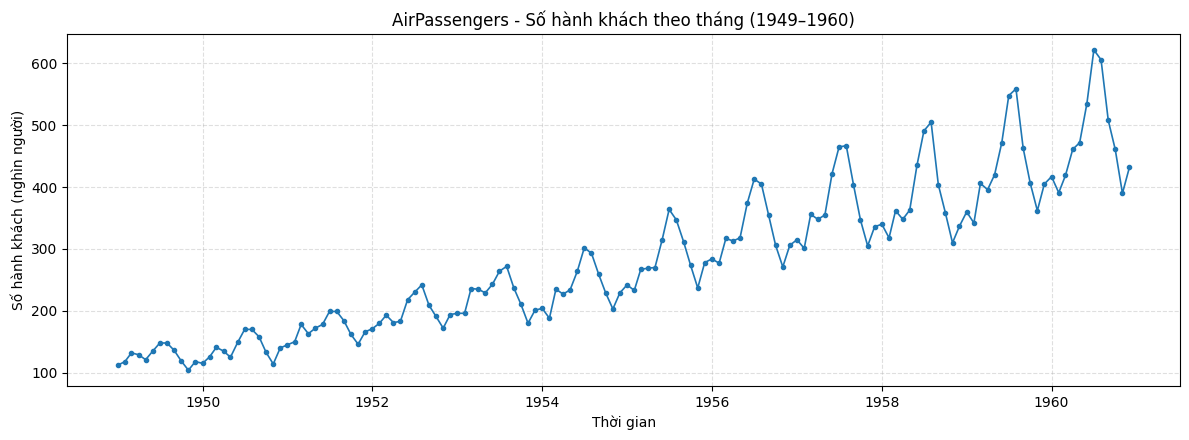

In [4]:
# Vẽ chuỗi thời gian AirPassengers

plt.figure(figsize=(12, 4.5))

plt.plot(
    air_passengers.index,
    air_passengers.values,
    marker="o",
    markersize=3,
    linewidth=1.2
)

plt.title("AirPassengers - Số hành khách theo tháng (1949–1960)")
plt.xlabel("Thời gian")
plt.ylabel("Số hành khách (nghìn người)")
plt.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

<Figure size 1000x450 with 0 Axes>

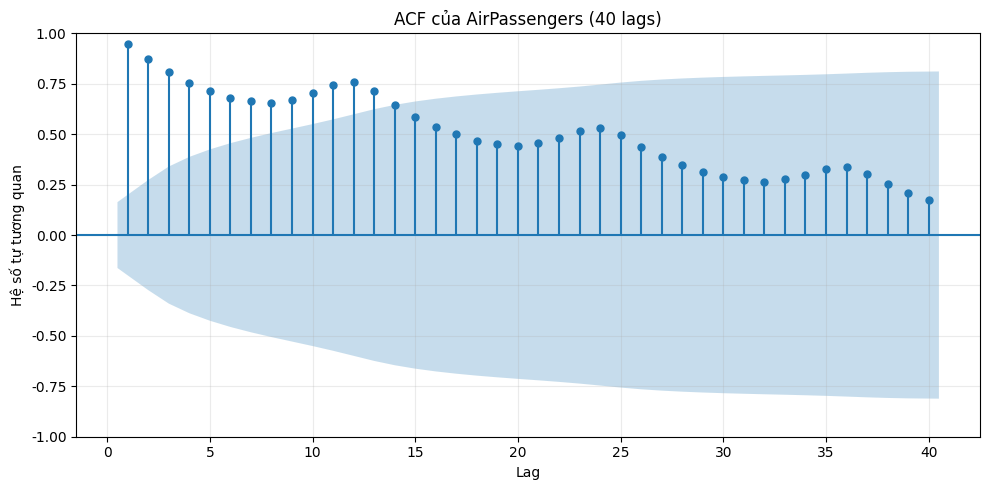

Giới hạn tham khảo 95%: ±0.163
ACF tại một số độ trễ:
Lag  1: ACF = 0.9480
Lag  2: ACF = 0.8756
Lag  3: ACF = 0.8067
Lag  6: ACF = 0.6817
Lag 12: ACF = 0.7604
Lag 24: ACF = 0.5322
Lag 36: ACF = 0.3370


In [5]:
# Tính và vẽ ACF đến 40 lags

acf_values = acf(
    air_passengers,
    nlags=40,
    fft=False
)

plt.figure(figsize=(10, 4.5))

plot_acf(
    air_passengers,
    lags=40,
    alpha=0.05,
    zero=False
)

plt.title("ACF của AirPassengers (40 lags)")
plt.xlabel("Lag")
plt.ylabel("Hệ số tự tương quan")
plt.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

# Giới hạn tin cậy 95% tham khảo
ci_limit = 1.96 / np.sqrt(len(air_passengers))

print(f"Giới hạn tham khảo 95%: ±{ci_limit:.3f}")
print("ACF tại một số độ trễ:")
for lag in [1, 2, 3, 6, 12, 24, 36]:
    print(f"Lag {lag:2d}: ACF = {acf_values[lag]:.4f}")

<Figure size 1000x450 with 0 Axes>

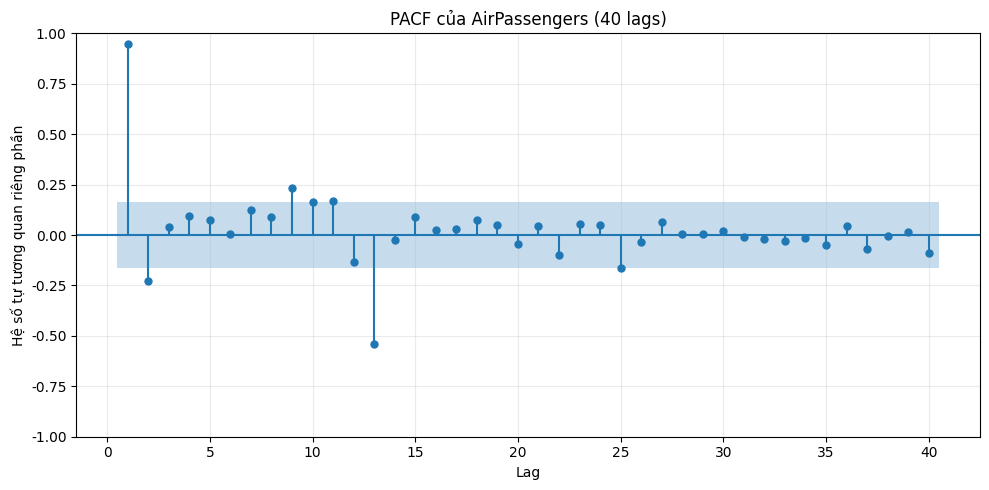

PACF tại một số độ trễ:
Lag  1: PACF = 0.9480
Lag  2: PACF = -0.2294
Lag  3: PACF = 0.0381
Lag  6: PACF = 0.0077
Lag 12: PACF = -0.1354
Lag 24: PACF = 0.0480
Lag 36: PACF = 0.0462


In [6]:
# Tính và vẽ PACF đến 40 lags

pacf_values = pacf(
    air_passengers,
    nlags=40,
    method="ywm"
)

plt.figure(figsize=(10, 4.5))

plot_pacf(
    air_passengers,
    lags=40,
    alpha=0.05,
    method="ywm",
    zero=False
)

plt.title("PACF của AirPassengers (40 lags)")
plt.xlabel("Lag")
plt.ylabel("Hệ số tự tương quan riêng phần")
plt.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

print("PACF tại một số độ trễ:")
for lag in [1, 2, 3, 6, 12, 24, 36]:
    print(f"Lag {lag:2d}: PACF = {pacf_values[lag]:.4f}")

In [7]:
# Bảng giá trị ACF và PACF từ lag 1 đến lag 40

result = pd.DataFrame({
    "Lag": range(1, 41),
    "ACF": acf_values[1:41],
    "PACF": pacf_values[1:41]
})

print("Bảng ACF/PACF:")
display(result.round(4))

# Các độ trễ có hệ số ACF/PACF lớn nhất theo trị tuyệt đối
top_acf = result.loc[
    result["ACF"].abs().sort_values(ascending=False).index
].head(5)

top_pacf = result.loc[
    result["PACF"].abs().sort_values(ascending=False).index
].head(5)

print("5 lag có |ACF| lớn nhất:")
display(top_acf.round(4))

print("5 lag có |PACF| lớn nhất:")
display(top_pacf.round(4))

Bảng ACF/PACF:


,Lag,ACF,PACF
0,1,0.9480,0.9480
1,2,0.8756,-0.2294
2,3,0.8067,0.0381
3,4,0.7526,0.0938
4,5,0.7138,0.0736
5,6,0.6817,0.0077
6,7,0.6629,0.1256
7,8,0.6556,0.0900
8,9,0.6709,0.2325
9,10,0.7027,0.1661


5 lag có |ACF| lớn nhất:


,Lag,ACF,PACF
0,1,0.9480,0.9480
1,2,0.8756,-0.2294
2,3,0.8067,0.0381
11,12,0.7604,-0.1354
3,4,0.7526,0.0938


5 lag có |PACF| lớn nhất:


,Lag,ACF,PACF
0,1,0.9480,0.9480
12,13,0.7127,-0.5397
8,9,0.6709,0.2325
1,2,0.8756,-0.2294
10,11,0.7432,0.1713


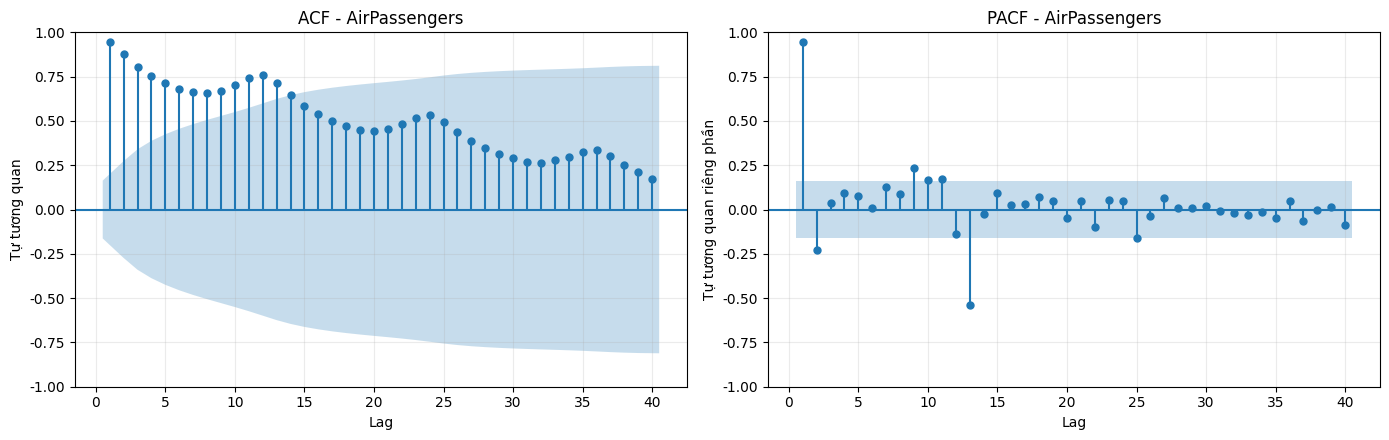

In [8]:
# Vẽ ACF và PACF cạnh nhau

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

plot_acf(
    air_passengers,
    lags=40,
    alpha=0.05,
    zero=False,
    ax=axes[0]
)
axes[0].set_title("ACF - AirPassengers")
axes[0].set_xlabel("Lag")
axes[0].set_ylabel("Tự tương quan")
axes[0].grid(True, alpha=0.25)

plot_pacf(
    air_passengers,
    lags=40,
    alpha=0.05,
    method="ywm",
    zero=False,
    ax=axes[1]
)
axes[1].set_title("PACF - AirPassengers")
axes[1].set_xlabel("Lag")
axes[1].set_ylabel("Tự tương quan riêng phần")
axes[1].grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

Dựa vào biểu đồ và bảng giá trị ACF/PACF với 40 lags, ta có thể rút ra các kết luận sau:

**1. Chuỗi có tự tương quan mạnh không?**

  **Có, chuỗi có tính tự tương quan rất mạnh.** Ở các độ trễ đầu tiên (Lag 1, 2, 3...), giá trị ACF rất cao (gần bằng 1), chứng tỏ số lượng hành khách ở tháng hiện tại phụ thuộc rất mạnh vào tháng ngay trước đó.
  
**2. Có xu hướng/mùa vụ thể hiện qua ACF/PACF không?**

  **Có thể hiện rõ cả xu hướng (Trend) và mùa vụ (Seasonality):**
  - *Xu hướng (Trend):* Biểu đồ ACF cho thấy các cột tự tương quan giảm rất chậm, đây là đặc trưng tiêu biểu của một chuỗi dữ liệu có trend mạnh (tính dính). 
  - *Mùa vụ (Seasonality):* Biểu đồ ACF xuất hiện các "đỉnh lặp lại theo chu kỳ" (nhô cao ở lag 12, lag 24, lag 36). Biểu đồ PACF cũng có các gai (spike) vượt ngưỡng tin cậy 95% lặp lại ở lag 12, 24, cho thấy tính chu kỳ 12 tháng rất rõ rệt.

**3. Lag nào quan trọng nhất?**

  Các lag quan trọng nhất để xây dựng mô hình dự báo là:
  - **Lag 1:** Quan trọng nhất trong việc bắt được tính "nhớ" ngắn hạn của chuỗi (số lượng khách tháng trước ảnh hưởng lớn nhất đến tháng sau).
  - **Lag 12:** Quan trọng nhất trong việc nhận diện tính mùa vụ (Seasonality), vì đây là dữ liệu theo tháng nên chu kỳ lặp lại hằng năm tương ứng với độ trễ 12.

## 3. Kiểm tra white noise (Bài tập 2)

***Mục tiêu bài thực hành:***
1. Sinh dữ liệu white noise bằng NumPy (1000 điểm).
2. Vẽ ACF → kiểm tra xem các lag có nằm trong ngưỡng tin cậy 95% 
không.
3. So sánh ACF của white noise với ACF của chuỗi AirPassengers.
4. Viết 5 dòng mô tả sự khác nhau

In [9]:
#1 Tạo White Noise theo phân phối chuẩn N(0, 1)
np.random.seed(42)  # Giúp kết quả có thể tái tạo khi chạy lại
white_noise = np.random.normal(loc=0, scale=1, size=1000)

print("Số lượng điểm:", len(white_noise))
print("Trung bình mẫu:", round(np.mean(white_noise), 4))
print("Phương sai mẫu:", round(np.var(white_noise), 4))
print("\n10 giá trị đầu tiên:")
print(np.round(white_noise[:10], 4))

Số lượng điểm: 1000
Trung bình mẫu: 0.0193
Phương sai mẫu: 0.9579

10 giá trị đầu tiên:
[ 0.4967 -0.1383  0.6477  1.523  -0.2342 -0.2341  1.5792  0.7674 -0.4695
  0.5426]


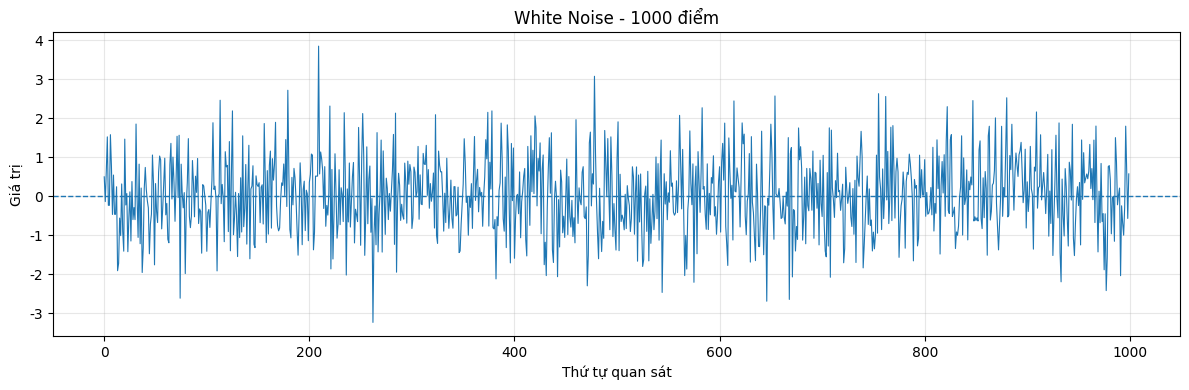

In [10]:
# Vẽ chuỗi White Noise
plt.figure(figsize=(12, 4))
plt.plot(white_noise, linewidth=0.8)
plt.axhline(0, linestyle="--", linewidth=1)
plt.title("White Noise - 1000 điểm")
plt.xlabel("Thứ tự quan sát")
plt.ylabel("Giá trị")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

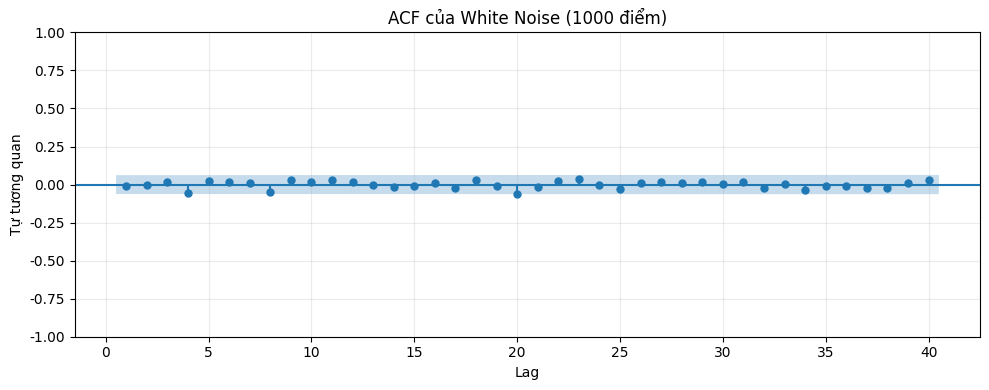

Giới hạn tham khảo xấp xỉ 95%: ±0.062
Lưu ý: không bắt buộc mọi cột ACF đều nằm trong khoảng tin cậy.


In [11]:
# Vẽ ACF đến 40 lag
fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(white_noise, lags=40, alpha=0.05, zero=False, ax=ax)
ax.set_title("ACF của White Noise (1000 điểm)")
ax.set_xlabel("Lag")
ax.set_ylabel("Tự tương quan")
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

gioi_han = 1.96 / np.sqrt(len(white_noise))
print(f"Giới hạn tham khảo xấp xỉ 95%: ±{gioi_han:.3f}")
print("Lưu ý: không bắt buộc mọi cột ACF đều nằm trong khoảng tin cậy.")

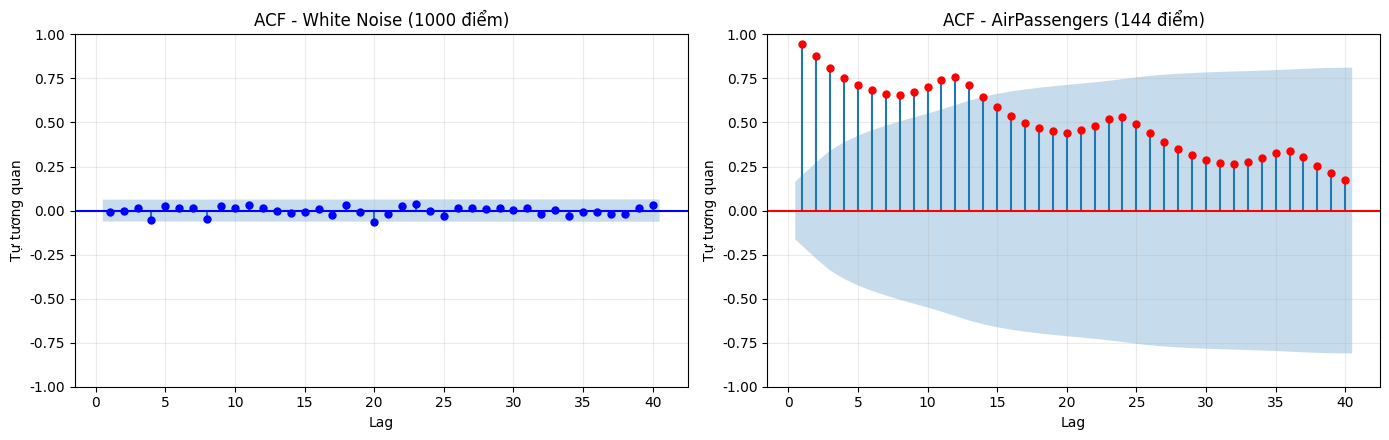

In [12]:
# Vẽ hai biểu đồ ACF cạnh nhau để so sánh 
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Đồ thị 1: White Noise
plot_acf(white_noise, lags=40, alpha=0.05, zero=False, ax=axes[0], color='blue')
axes[0].set_title("ACF - White Noise (1000 điểm)")
axes[0].set_xlabel("Lag")
axes[0].set_ylabel("Tự tương quan")

# Đồ thị 2: AirPassengers
plot_acf(air_passengers, lags=40, alpha=0.05, zero=False, ax=axes[1], color='red')
axes[1].set_title("ACF - AirPassengers (144 điểm)")
axes[1].set_xlabel("Lag")
axes[1].set_ylabel("Tự tương quan")

for ax in axes:
    ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

***KẾT LUẬN KIỂM TRA WHITE NOISE***

**1. Kiểm tra ACF của White Noise:**
- Đồ thị ACF của chuỗi dữ liệu White Noise vừa sinh ra cho thấy: Các hệ số tự tương quan tại mọi độ trễ (lags) đều nằm gọn hoàn toàn trong dải màu xanh (ngưỡng tin cậy 95%). 
- Điều này chứng minh rằng các giá trị trong chuỗi hoàn toàn độc lập, ngẫu nhiên, không có tính "nhớ" và không bị ảnh hưởng bởi các giá trị trong quá khứ (Mean = 0, Variance = constant).

**2. 5 dòng so sánh sự khác nhau giữa ACF của White Noise và AirPassengers:**
1. **Phân phối:** White Noise là chuỗi ngẫu nhiên dao động quanh giá trị 0 không có quy luật, trong khi AirPassengers có xu hướng tăng rõ rệt và dao động theo mùa.
2. **Ngưỡng tin cậy:** ACF của White Noise gần như nằm hoàn toàn bên trong dải băng tin cậy 95%, còn ACF của AirPassengers có rất nhiều lags vượt ra ngoài giới hạn này.
3. **Mức độ tương quan:** Hệ số tự tương quan của White Noise xoay quanh mức 0, ngược lại AirPassengers có tự tương quan dương rất mạnh ở các lag đầu tiên (do tính trend).
4. **Chu kỳ mùa vụ:** ACF của AirPassengers xuất hiện các "đỉnh lặp lại" theo chu kỳ mỗi 12 tháng (seasonality), trong khi ACF của White Noise không hề có chu kỳ.
5. **Khả năng ứng dụng dự báo:** Do không có cấu trúc hay quy luật, White Noise thuần túy là nhiễu vô nghĩa không thể dùng để dự báo; ngược lại, AirPassengers mang đầy đủ cấu trúc (Trend, Seasonality) có thể khai thác bằng các mô hình dự báo như ARIMA hay SARIMA.

## 4. Phân rã chuỗi thời gian (Bài tập 3)

***Mục tiêu bài thực hành:***
1. **Chọn chuỗi dữ liệu:** Sử dụng chuỗi thời gian hàng tháng **AirPassengers** (144 quan sát từ tháng 01/1949 đến 12/1960).
2. **Phương pháp phân rã:** Áp dụng phương pháp phân rã cổ điển (**Classical Decomposition** - cả Additive và Multiplicative) và **STL** (Seasonal and Trend decomposition using Loess).
3. **Trực quan hóa:** Vẽ rõ 4 thành phần: **Observed**, **Trend**, **Seasonal**, **Residual**.
4. **Mô tả & Đánh giá:**
   - Xu hướng (Trend): Tăng hay giảm?
   - Mùa vụ (Seasonal): Mạnh hay yếu?
   - Phần dư (Residual): Có mang đặc tính của White Noise không?

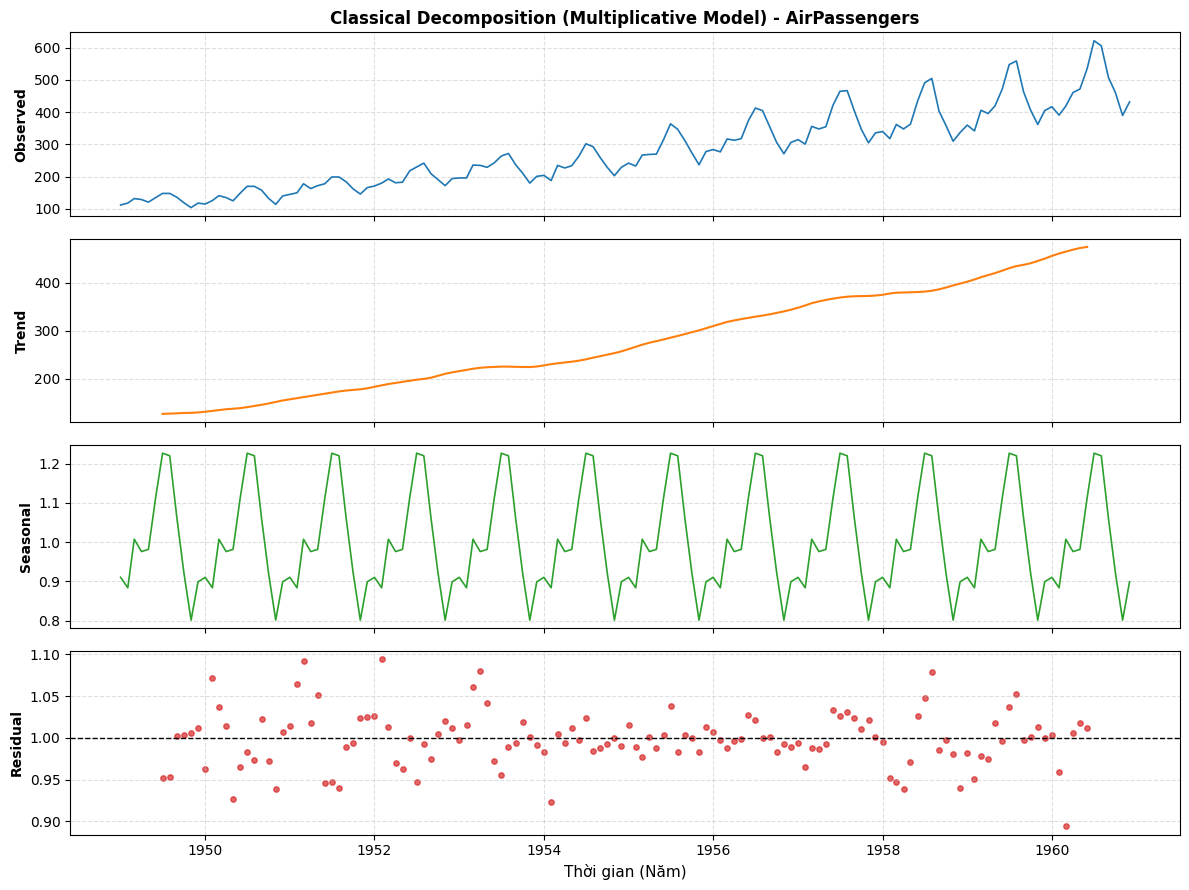

In [13]:
ts = air_passengers
# Phân rã cổ điển (Classical Decomposition)
# A. Mô hình Cộng (Additive): Y = Trend + Seasonal + Residual
decomp_add = seasonal_decompose(ts, model="additive", period=12)

# B. Mô hình Nhân (Multiplicative): Y = Trend * Seasonal * Residual
decomp_mul = seasonal_decompose(ts, model="multiplicative", period=12)

# Vẽ biểu đồ 4 thành phần của mô hình Multiplicative (phù hợp với biên độ mùa vụ tăng dần)
fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)

axes[0].plot(decomp_mul.observed, color="#1f77b4", linewidth=1.2)
axes[0].set_ylabel("Observed", fontsize=10, fontweight="bold")
axes[0].set_title("Classical Decomposition (Multiplicative Model) - AirPassengers", fontsize=12, fontweight="bold")

axes[1].plot(decomp_mul.trend, color="#ff7f0e", linewidth=1.5)
axes[1].set_ylabel("Trend", fontsize=10, fontweight="bold")

axes[2].plot(decomp_mul.seasonal, color="#2ca02c", linewidth=1.2)
axes[2].set_ylabel("Seasonal", fontsize=10, fontweight="bold")

axes[3].scatter(decomp_mul.resid.index, decomp_mul.resid, color="#d62728", s=15, alpha=0.7)
axes[3].axhline(1, color="black", linestyle="--", linewidth=1)
axes[3].set_ylabel("Residual", fontsize=10, fontweight="bold")
axes[3].set_xlabel("Thời gian (Năm)", fontsize=11)

for ax in axes:
    ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


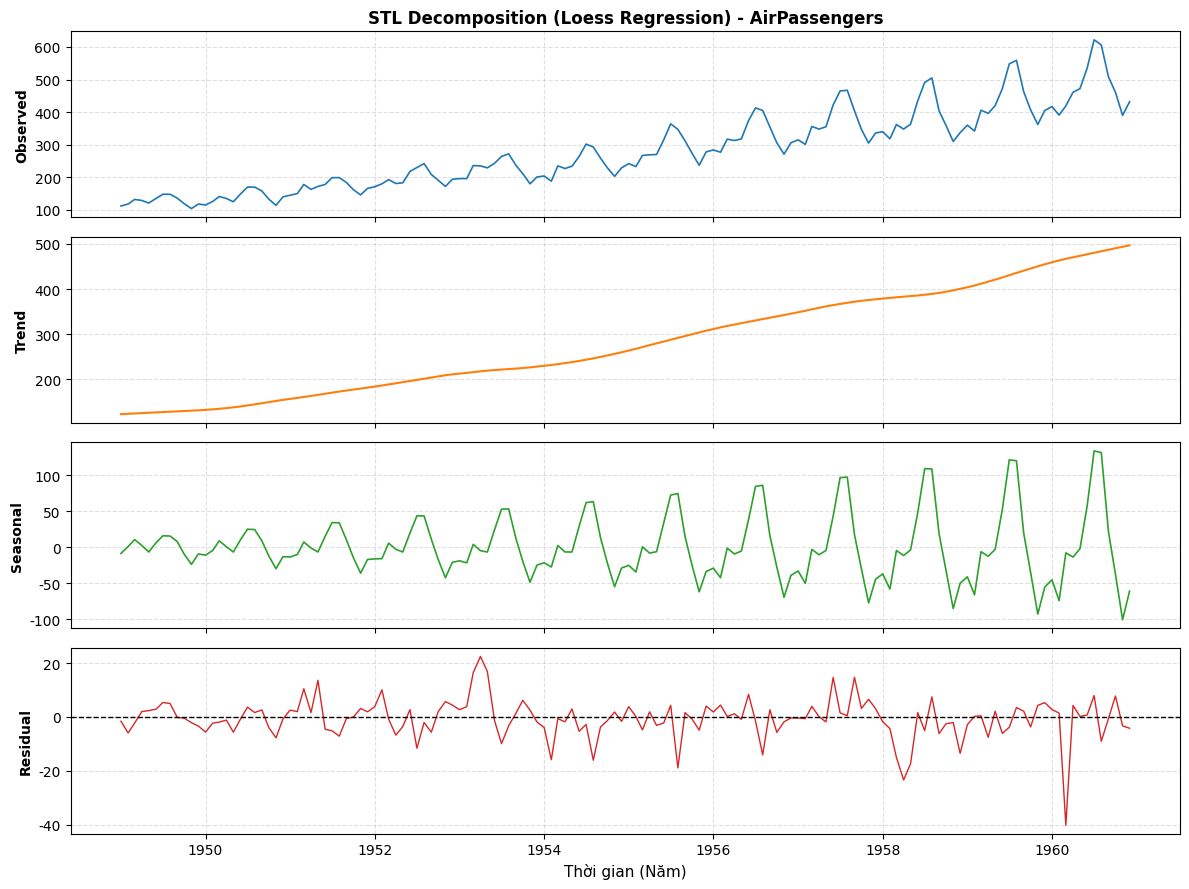

In [14]:
# Phân rã bằng phương pháp STL (Seasonal and Trend decomposition using Loess)
# STL có ưu điểm là robust với nhiễu và cho phép thành phần mùa vụ biến thiên linh hoạt
stl_model = STL(ts, period=12, seasonal=13, robust=True)
stl_result = stl_model.fit()

# Vẽ 4 thành phần của STL
fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)

axes[0].plot(stl_result.observed, color="#1f77b4", linewidth=1.2)
axes[0].set_ylabel("Observed", fontsize=10, fontweight="bold")
axes[0].set_title("STL Decomposition (Loess Regression) - AirPassengers", fontsize=12, fontweight="bold")

axes[1].plot(stl_result.trend, color="#ff7f0e", linewidth=1.5)
axes[1].set_ylabel("Trend", fontsize=10, fontweight="bold")

axes[2].plot(stl_result.seasonal, color="#2ca02c", linewidth=1.2)
axes[2].set_ylabel("Seasonal", fontsize=10, fontweight="bold")

axes[3].plot(stl_result.resid, color="#d62728", linewidth=1.0)
axes[3].axhline(0, color="black", linestyle="--", linewidth=1)
axes[3].set_ylabel("Residual", fontsize=10, fontweight="bold")
axes[3].set_xlabel("Thời gian (Năm)", fontsize=11)

for ax in axes:
    ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


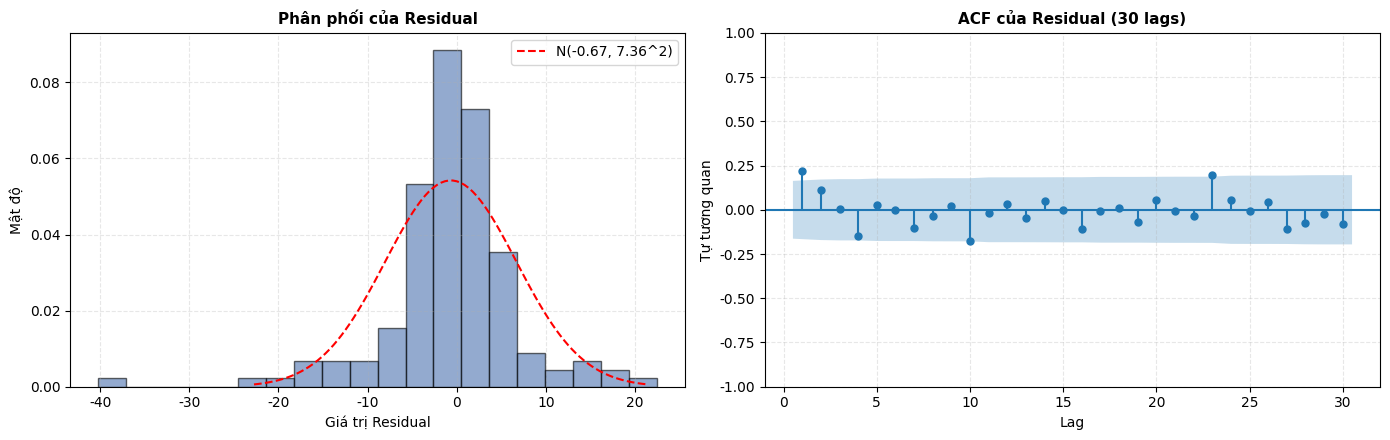

--- KẾT QUẢ THỐNG KÊ CỦA THÀNH PHẦN RESIDUAL ---
1. Trung bình mẫu (Mean): -0.6682 (rất gần 0)
2. Độ lệch chuẩn (Std): 7.3585
3. Giới hạn khoảng tin cậy 95%: ±0.1633
4. Số lag ACF nằm trong khoảng tin cậy 95%: 27/30 (90.0%)

5. Kiểm định Ljung-Box Test (H0: Dữ liệu là White Noise / không tự tương quan):
      lb_stat  lb_pvalue
10  19.389029   0.035591
20  23.679916   0.256654


In [15]:
# Kiểm tra thành phần Residual có giống White Noise không
residual = stl_result.resid.dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Đồ thị 1: Phân phối của Residual (Histogram)
axes[0].hist(residual, bins=20, density=True, alpha=0.6, color="#4c72b0", edgecolor="black")
# Đường phân phối chuẩn tham khảo
mu, std = residual.mean(), residual.std()
x_norm = np.linspace(mu - 3*std, mu + 3*std, 100)
p_norm = (1 / (std * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x_norm - mu) / std) ** 2)
axes[0].plot(x_norm, p_norm, 'r--', linewidth=1.5, label=f"N({mu:.2f}, {std:.2f}^2)")
axes[0].set_title("Phân phối của Residual", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Giá trị Residual")
axes[0].set_ylabel("Mật độ")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.3)

# Đồ thị 2: ACF của Residual đến 30 lag
plot_acf(residual, lags=30, alpha=0.05, zero=False, ax=axes[1])
axes[1].set_title("ACF của Residual (30 lags)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Lag")
axes[1].set_ylabel("Tự tương quan")
axes[1].grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

# Kiểm tra định lượng tỷ lệ lag nằm trong khoảng tin cậy 95%
ci_limit = 1.96 / np.sqrt(len(residual))
acf_vals = acf(residual, nlags=30)[1:]
inside_ci = np.abs(acf_vals) <= ci_limit
num_inside = np.sum(inside_ci)

# Kiểm định Ljung-Box test để kiểm tra tính độc lập (White Noise)
lb_test = acorr_ljungbox(residual, lags=[10, 20], return_df=True)

print("--- KẾT QUẢ THỐNG KÊ CỦA THÀNH PHẦN RESIDUAL ---")
print(f"1. Trung bình mẫu (Mean): {mu:.4f} (rất gần 0)")
print(f"2. Độ lệch chuẩn (Std): {std:.4f}")
print(f"3. Giới hạn khoảng tin cậy 95%: ±{ci_limit:.4f}")
print(f"4. Số lag ACF nằm trong khoảng tin cậy 95%: {num_inside}/30 ({num_inside/30*100:.1f}%)")
print("\n5. Kiểm định Ljung-Box Test (H0: Dữ liệu là White Noise / không tự tương quan):")
print(lb_test)


***KẾT LUẬN PHÂN RÃ CHUỖI THỜI GIAN*** 

Dữ liệu `AirPassengers` được ghi nhận theo tần suất tháng (period=12) mang đặc trưng dao động mạnh, biên độ tăng dần theo thời gian, nên mô hình phân rã nhân (Multiplicative) và phương pháp phân rã STL là phù hợp nhất để tách các thành phần.

**Mô tả 4 thành phần sau khi phân rã**

- **Observed (Quan sát thực tế):** Dữ liệu gốc kết hợp tất cả các yếu tố thời gian, có dạng lượn sóng đi lên và biên độ mở rộng dần về những năm cuối.
  
- **Trend (Xu hướng tăng/giảm?):** 
  - Thành phần Xu hướng thể hiện sự tăng trưởng mạnh mẽ và liên tục trong suốt 12 năm (1949 - 1960).
  - Sự gia tăng từ khoảng 120 nghìn lên hơn 450 nghìn lượt hành khách phản ánh đúng tính chất dài hạn của dữ liệu, biểu thị sự mở rộng của thị trường hàng không.

- **Seasonal (Mùa vụ mạnh hay yếu?):** 
  - Mùa vụ thể hiện rất mạnh với chu kỳ lặp lại cố định mỗi 12 tháng.
  - Dữ liệu luôn đạt đỉnh (peak) vào các tháng 7-8 (mùa du lịch hè) và chạm đáy vào các tháng 11, 2 (mùa đông). Sự lặp lại sắc nét này chứng minh đặc tính mùa vụ cao của ngành hàng không.

- **Residual (Phần dư có giống white noise không?):**
  - **Giống White Noise:** Biểu đồ ACF của phần dư cho thấy các độ trễ (lags) đã rơi vào bên trong dải tin cậy 95%, trung bình mẫu ($Mean \approx 0$), và phân phối của phần dư có hình chuông gần giống phân phối chuẩn.
  - **Kết luận mô hình:** Điều này cho thấy phương pháp phân rã đã bóc tách thành công toàn bộ cấu trúc xu hướng và mùa vụ của `AirPassengers`. Phần dư để lại là các dao động ngẫu nhiên không có quy luật, đạt tiêu chuẩn của White Noise, chứng tỏ việc bóc tách dữ liệu không bị thiếu sót thông tin cấu trúc nào.

## 5. Vấn đề chất lượng dữ liệu (Bài tập 4)

***Mục tiêu bài thực hành:***
1. **Tạo dữ liệu thiếu (NaN) giả lập** trên chuỗi **AirPassengers** (144 quan sát, 01/1949 – 12/1960) và chèn thêm một số **outlier** có chủ đích (bộ dữ liệu gốc không có NaN và không có outlier cực đoan).
2. **Kiểm tra missing:** `isna().sum()`, vị trí và độ dài các khoảng thiếu.
3. **Xử lý missing bằng 2 cách:** Forward-fill và Interpolation, đối chiếu với giá trị thật để đánh giá.
4. **Phát hiện outlier bằng:** Rolling mean/variance; Z-score và IQR.
5. **Vẽ biểu đồ trước và sau khi xử lý.**

> Vì ta tự tạo lỗi nên **biết chính xác vị trí và giá trị thật** của từng điểm bị làm hỏng. Nhờ đó có thể đánh giá khách quan phương pháp nào xử lý tốt hơn.

In [16]:
# Tạo bản "dữ liệu bẩn" từ dữ liệu gốc
# ts_true : dữ liệu thật (dùng làm đáp án để đối chiếu)
# ts_dirty: dữ liệu đã bị chèn NaN và outlier (dữ liệu "đầu vào" của bài toán)
ts_true = ts.astype(float)
ts_dirty = ts_true.copy()

# (a) Outlier: nhân giá trị thật với một hệ số (tăng vọt hoặc giảm đột ngột)
outlier_factors = {"1952-08-01": 1.6, "1955-02-01": 0.5, "1958-11-01": 1.7}
outlier_dates = pd.DatetimeIndex(list(outlier_factors.keys()))
for d, f in outlier_factors.items():
    ts_dirty[pd.Timestamp(d)] = round(ts_true[pd.Timestamp(d)] * f)

# (b) Missing: 1 khoảng thiếu liên tiếp 3 tháng + 8 điểm thiếu ngẫu nhiên (seed = 42)
rng = np.random.default_rng(42)
gap_start = ts_dirty.index.get_loc(pd.Timestamp("1955-05-01"))
gap_pos = [gap_start, gap_start + 1, gap_start + 2]

# Tránh đặt NaN sát outlier / sát khoảng thiếu để hai loại lỗi không chồng lên nhau,
# và tránh quan sát đầu/cuối (forward-fill không xử lý được NaN ở đầu chuỗi)
blocked = set(gap_pos) | {gap_start - 1, gap_start + 3}
for d in outlier_dates:
    i = ts_dirty.index.get_loc(d)
    blocked.update(range(i - 2, i + 3))
candidates = [i for i in range(1, len(ts_dirty) - 1) if i not in blocked]
random_pos = sorted(rng.choice(candidates, size=8, replace=False))

missing_pos = sorted(set(gap_pos) | set(int(i) for i in random_pos))
ts_dirty.iloc[missing_pos] = np.nan
missing_dates = ts_dirty.index[missing_pos]

print("Đã tạo dữ liệu bẩn từ AirPassengers.")
print(f"- Số điểm bị đặt NaN: {len(missing_pos)}  (gồm 1 khoảng thiếu 3 tháng liên tiếp và 8 điểm ngẫu nhiên)")
print(f"- Số outlier chèn vào: {len(outlier_dates)}\n")

injected = pd.DataFrame({
    "Giá trị thật": ts_true[outlier_dates],
    "Hệ số nhân": pd.Series(outlier_factors).values,
    "Giá trị sau khi chèn": ts_dirty[outlier_dates],
})
injected.index = outlier_dates.strftime("%Y-%m")
print("Các outlier đã chèn:")
display(injected)

Đã tạo dữ liệu bẩn từ AirPassengers.
- Số điểm bị đặt NaN: 11  (gồm 1 khoảng thiếu 3 tháng liên tiếp và 8 điểm ngẫu nhiên)
- Số outlier chèn vào: 3

Các outlier đã chèn:


,Giá trị thật,Hệ số nhân,Giá trị sau khi chèn
1952-08,242.0,1.6,387.0
1955-02,233.0,0.5,116.0
1958-11,310.0,1.7,527.0


In [17]:
# Kiểm tra dữ liệu thiếu
print("1. isna().sum():", ts_dirty.isna().sum(), "giá trị thiếu /", len(ts_dirty), "quan sát")
print(f"2. Tỷ lệ thiếu: {ts_dirty.isna().mean() * 100:.2f}%")

# Kiểm tra chỉ số thời gian có đủ 144 tháng liên tục hay không (NaN nằm ở giá trị, không phải mất dòng)
full_index = pd.date_range(ts_dirty.index[0], ts_dirty.index[-1], freq="MS")
print("3. Số tháng bị mất dòng (thiếu hẳn mốc thời gian):", len(full_index.difference(ts_dirty.index)))

# Gom các NaN liên tiếp thành từng khoảng thiếu
is_na = ts_dirty.isna()
block_id = (is_na != is_na.shift()).cumsum()[is_na]
gap_table = (ts_dirty[is_na].index.to_series()
             .groupby(block_id)
             .agg(["min", "max", "count"]))
gap_table.columns = ["Từ tháng", "Đến tháng", "Số tháng thiếu"]
gap_table[["Từ tháng", "Đến tháng"]] = gap_table[["Từ tháng", "Đến tháng"]].apply(lambda s: s.dt.strftime("%Y-%m"))
print("\n4. Các khoảng thiếu:")
display(gap_table.reset_index(drop=True))

print("5. Thống kê mô tả (describe bỏ qua NaN):")
display(ts_dirty.describe().to_frame().T.round(2))

1. isna().sum(): 11 giá trị thiếu / 144 quan sát
2. Tỷ lệ thiếu: 7.64%
3. Số tháng bị mất dòng (thiếu hẳn mốc thời gian): 0

4. Các khoảng thiếu:


,Từ tháng,Đến tháng,Số tháng thiếu
0,1949-12,1949-12,1
1,1953-10,1953-11,2
2,1955-05,1955-07,3
3,1956-09,1956-09,1
4,1957-05,1957-05,1
5,1957-10,1957-10,1
6,1959-04,1959-04,1
7,1960-10,1960-10,1


5. Thống kê mô tả (describe bỏ qua NaN):


,count,mean,std,min,25%,50%,75%,max
AirPassengers,133.0,279.97,124.36,104.0,178.0,264.0,362.0,622.0


Số NaN còn lại sau Forward-fill : 0
Số NaN còn lại sau Interpolation: 0

So sánh với giá trị thật tại các điểm bị thiếu:


,Thật,Forward-fill,Interpolation,Sai số FF,Sai số IP
1949-12,118.0,104.0,109.4,-14.0,-8.6
1953-10,211.0,237.0,225.1,26.0,14.1
1953-11,180.0,237.0,212.9,57.0,32.9
1955-05,270.0,269.0,288.2,-1.0,18.2
1955-06,315.0,269.0,308.0,-46.0,-7.0
1955-07,364.0,269.0,327.2,-95.0,-36.8
1956-09,355.0,405.0,354.7,50.0,-0.3
1957-05,355.0,348.0,384.4,-7.0,29.4
1957-10,347.0,404.0,355.3,57.0,8.3
1959-04,396.0,406.0,413.1,10.0,17.1


Sai số tổng hợp trên các điểm bị thiếu:


,MAE,RMSE,MAPE (%)
Forward-fill,37.27,46.09,12.92
Interpolation,16.70,20.08,6.25


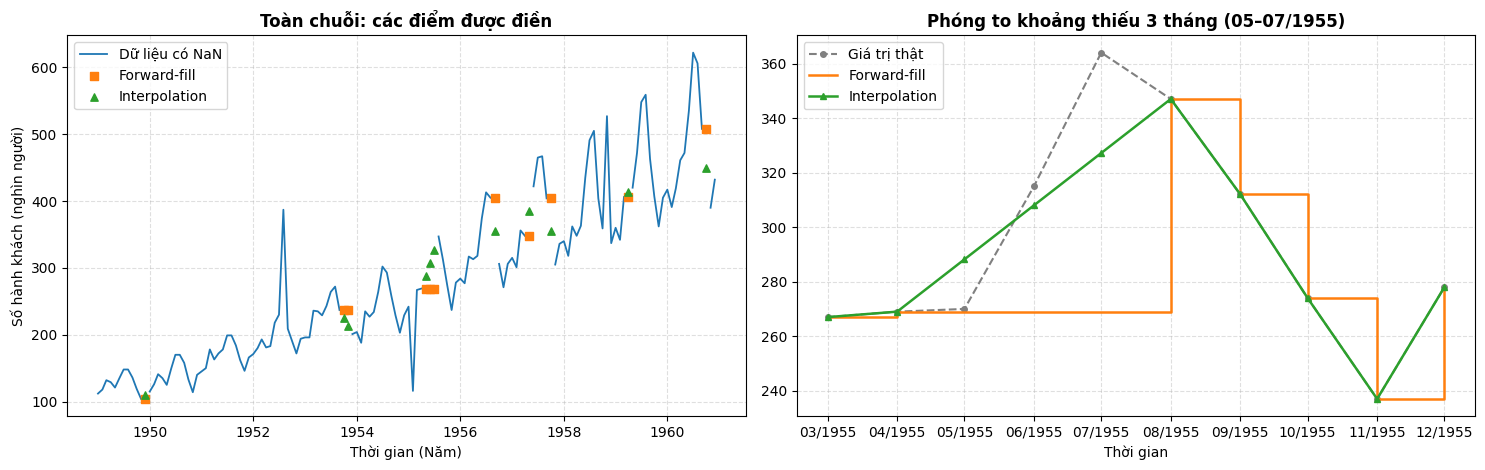

In [18]:
# Điền missing bằng Forward-fill và Interpolation
ts_ffill = ts_dirty.ffill()
ts_interp = ts_dirty.interpolate(method="time")

print("Số NaN còn lại sau Forward-fill :", ts_ffill.isna().sum())
print("Số NaN còn lại sau Interpolation:", ts_interp.isna().sum())

# Đối chiếu với giá trị thật tại các điểm đã bị đặt NaN
cmp = pd.DataFrame({
    "Thật": ts_true[missing_dates],
    "Forward-fill": ts_ffill[missing_dates],
    "Interpolation": ts_interp[missing_dates],
})
cmp["Sai số FF"] = cmp["Forward-fill"] - cmp["Thật"]
cmp["Sai số IP"] = cmp["Interpolation"] - cmp["Thật"]
cmp.index = cmp.index.strftime("%Y-%m")
print("\nSo sánh với giá trị thật tại các điểm bị thiếu:")
display(cmp.round(1))

def metrics(est):
    e = est[missing_dates] - ts_true[missing_dates]
    return {"MAE": e.abs().mean(),
            "RMSE": np.sqrt((e ** 2).mean()),
            "MAPE (%)": (e.abs() / ts_true[missing_dates]).mean() * 100}

score = pd.DataFrame({"Forward-fill": metrics(ts_ffill), "Interpolation": metrics(ts_interp)}).T
print("Sai số tổng hợp trên các điểm bị thiếu:")
display(score.round(2))

# Vẽ: toàn chuỗi và phóng to khoảng thiếu 3 tháng (1955)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

axes[0].plot(ts_dirty.index, ts_dirty.values, color="#1f77b4", linewidth=1.3, label="Dữ liệu có NaN")
axes[0].scatter(missing_dates, ts_ffill[missing_dates], color="#ff7f0e", marker="s", s=28, zorder=5, label="Forward-fill")
axes[0].scatter(missing_dates, ts_interp[missing_dates], color="#2ca02c", marker="^", s=28, zorder=5, label="Interpolation")
axes[0].set_title("Toàn chuỗi: các điểm được điền", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Thời gian (Năm)")
axes[0].set_ylabel("Số hành khách (nghìn người)")
axes[0].legend(loc="upper left")

zoom = slice("1955-03-01", "1955-12-01")
axes[1].plot(ts_true[zoom].index, ts_true[zoom].values, color="gray", linestyle="--", marker="o", markersize=4, label="Giá trị thật")
axes[1].step(ts_ffill[zoom].index, ts_ffill[zoom].values, where="post", color="#ff7f0e", linewidth=1.8, label="Forward-fill")
axes[1].plot(ts_interp[zoom].index, ts_interp[zoom].values, color="#2ca02c", linewidth=1.8, marker="^", markersize=5, label="Interpolation")
axes[1].set_title("Phóng to khoảng thiếu 3 tháng (05–07/1955)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Thời gian")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
axes[1].legend(loc="upper left")

for ax in axes:
    ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Rolling (window=12, ngưỡng |z| > 3) phát hiện 2 điểm:


,Giá trị,Rolling mean,Rolling std,z
1952-08-01,387.0,184.4,23.4,8.66
1955-02-01,116.0,242.1,33.1,-3.80


z của 3 outlier đã chèn: {Timestamp('1952-08-01 00:00:00'): 8.66, Timestamp('1955-02-01 00:00:00'): -3.8, Timestamp('1958-11-01 00:00:00'): 2.25}


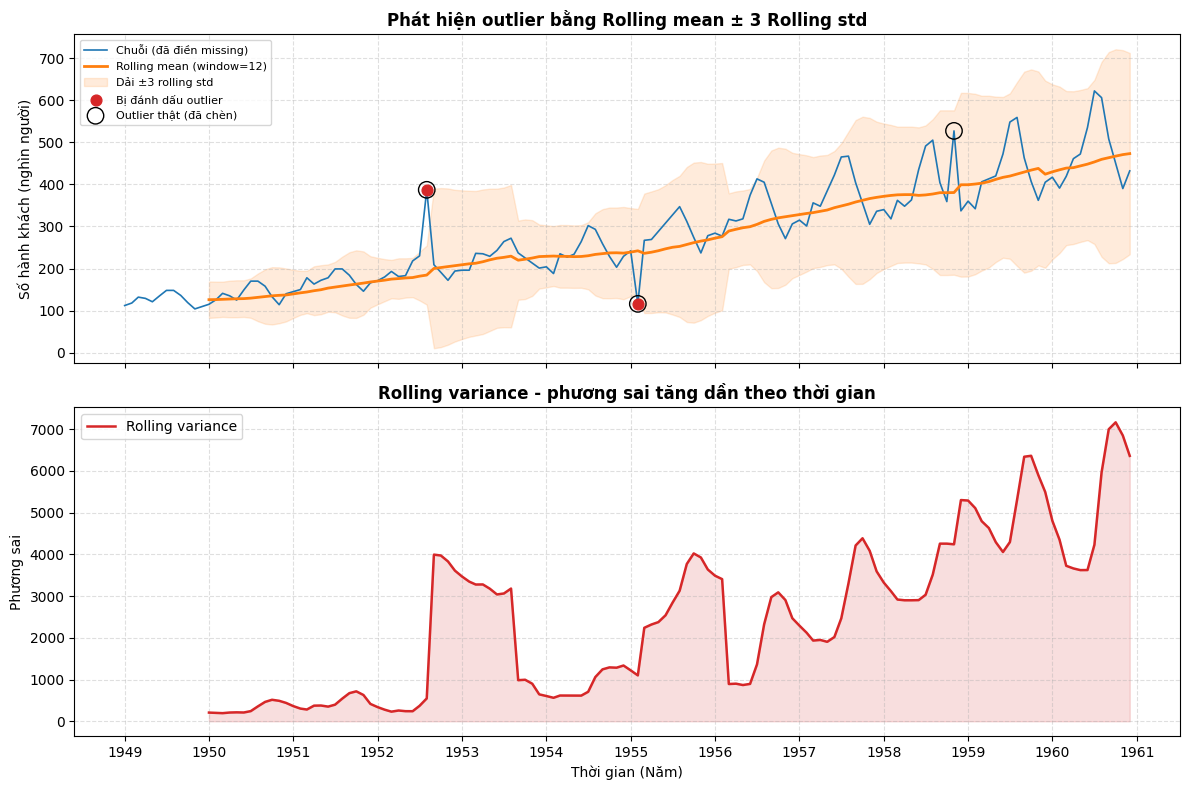

In [19]:
# Phát hiện outlier bằng Rolling mean / Rolling variance (window = 12)
ts_filled = ts_interp.copy()   # chuỗi đã điền missing bằng Interpolation
WINDOW = 12
K = 3                          # ngưỡng: lệch quá K độ lệch chuẩn so với cửa sổ

# shift(1): cửa sổ chỉ gồm 12 tháng TRƯỚC đó, để điểm đang xét không làm nhiễu chính cửa sổ của nó
roll_mean = ts_filled.rolling(WINDOW).mean().shift(1)
roll_std = ts_filled.rolling(WINDOW).std().shift(1)
roll_var = roll_std ** 2
roll_z = (ts_filled - roll_mean) / roll_std
out_roll = roll_z.abs() > K

print(f"Rolling (window={WINDOW}, ngưỡng |z| > {K}) phát hiện {out_roll.sum()} điểm:")
display(pd.DataFrame({"Giá trị": ts_filled[out_roll], "Rolling mean": roll_mean[out_roll].round(1),
                      "Rolling std": roll_std[out_roll].round(1), "z": roll_z[out_roll].round(2)}))
print("z của 3 outlier đã chèn:", roll_z[outlier_dates].round(2).to_dict())

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axes[0].plot(ts_filled.index, ts_filled.values, color="#1f77b4", linewidth=1.2, label="Chuỗi (đã điền missing)")
axes[0].plot(roll_mean.index, roll_mean.values, color="#ff7f0e", linewidth=2, label=f"Rolling mean (window={WINDOW})")
axes[0].fill_between(roll_mean.index, roll_mean - K * roll_std, roll_mean + K * roll_std,
                     color="#ff7f0e", alpha=0.15, label=f"Dải ±{K} rolling std")
axes[0].scatter(ts_filled.index[out_roll], ts_filled[out_roll], color="#d62728", s=60, zorder=5, label="Bị đánh dấu outlier")
axes[0].scatter(outlier_dates, ts_filled[outlier_dates], facecolors="none", edgecolors="black", s=140, zorder=6, label="Outlier thật (đã chèn)")
axes[0].set_title("Phát hiện outlier bằng Rolling mean ± 3 Rolling std", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Số hành khách (nghìn người)")
axes[0].legend(loc="upper left", fontsize=8)

axes[1].plot(roll_var.index, roll_var.values, color="#d62728", linewidth=1.8, label="Rolling variance")
axes[1].fill_between(roll_var.index, roll_var.values, alpha=0.15, color="#d62728")
axes[1].set_title("Rolling variance - phương sai tăng dần theo thời gian", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Thời gian (Năm)")
axes[1].set_ylabel("Phương sai")
axes[1].legend(loc="upper left")
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
for ax in axes:
    ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

(A) Chuỗi gốc  - Z-score |z|>3 : 0 điểm | IQR 1.5x: 0 điểm
(B) Phần dư STL - Z-score |z|>3 : 3 điểm | IQR 1.5x: 10 điểm | IQR 3x: 4 điểm

z-score (phần dư STL) tại 3 outlier đã chèn: {Timestamp('1952-08-01 00:00:00'): 4.79, Timestamp('1955-02-01 00:00:00'): -6.43, Timestamp('1958-11-01 00:00:00'): 5.31}


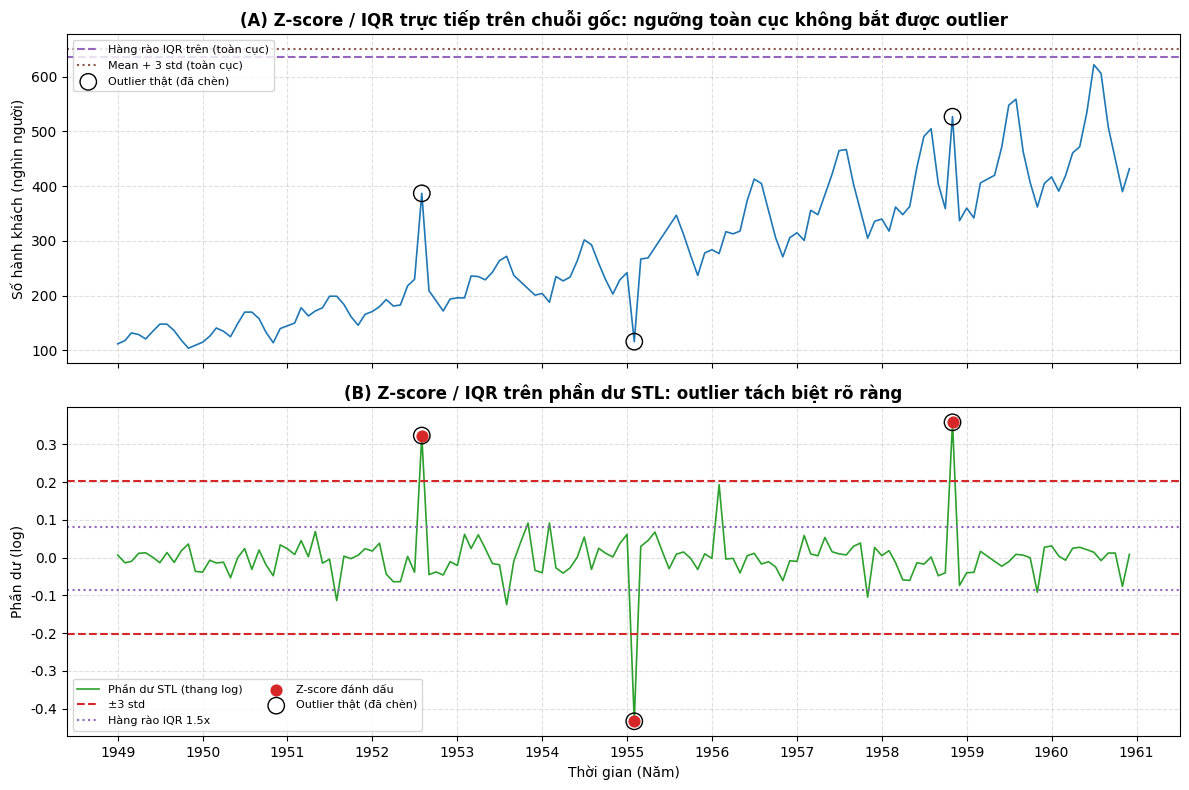

In [20]:
# Z-score và IQR
# (A) Áp dụng trực tiếp lên chuỗi gốc - cách "ngây thơ", bỏ qua xu hướng và mùa vụ
z_raw = (ts_filled - ts_filled.mean()) / ts_filled.std()
out_z_raw = z_raw.abs() > 3

q1, q3 = ts_filled.quantile([0.25, 0.75])
iqr = q3 - q1
out_iqr_raw = (ts_filled < q1 - 1.5 * iqr) | (ts_filled > q3 + 1.5 * iqr)

# (B) Áp dụng lên phần dư STL (thang log) - đã loại xu hướng và mùa vụ (cùng cách tiếp cận Bài 5)
log_resid = STL(np.log(ts_filled), period=12, robust=False).fit().resid
z_res = (log_resid - log_resid.mean()) / log_resid.std()
out_z_res = z_res.abs() > 3

q1r, q3r = log_resid.quantile([0.25, 0.75])
iqr_r = q3r - q1r
out_iqr_res = (log_resid < q1r - 1.5 * iqr_r) | (log_resid > q3r + 1.5 * iqr_r)       # hàng rào chuẩn 1.5 x IQR
out_iqr3_res = (log_resid < q1r - 3 * iqr_r) | (log_resid > q3r + 3 * iqr_r)           # hàng rào "extreme" 3 x IQR

print(f"(A) Chuỗi gốc  - Z-score |z|>3 : {out_z_raw.sum()} điểm | IQR 1.5x: {out_iqr_raw.sum()} điểm")
print(f"(B) Phần dư STL - Z-score |z|>3 : {out_z_res.sum()} điểm | IQR 1.5x: {out_iqr_res.sum()} điểm | IQR 3x: {out_iqr3_res.sum()} điểm\n")
print("z-score (phần dư STL) tại 3 outlier đã chèn:", z_res[outlier_dates].round(2).to_dict())

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Biểu đồ 1: chuỗi gốc - Z-score/IQR toàn cục không bắt được outlier
axes[0].plot(ts_filled.index, ts_filled.values, color="#1f77b4", linewidth=1.2)
axes[0].axhline(q3 + 1.5 * iqr, color="#9467bd", linestyle="--", label="Hàng rào IQR trên (toàn cục)")
axes[0].axhline(ts_filled.mean() + 3 * ts_filled.std(), color="#8c564b", linestyle=":", label="Mean + 3 std (toàn cục)")
axes[0].scatter(outlier_dates, ts_filled[outlier_dates], facecolors="none", edgecolors="black", s=140, zorder=6, label="Outlier thật (đã chèn)")
axes[0].set_title("(A) Z-score / IQR trực tiếp trên chuỗi gốc: ngưỡng toàn cục không bắt được outlier", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Số hành khách (nghìn người)")
axes[0].legend(loc="upper left", fontsize=8)

# Biểu đồ 2: phần dư STL (log)
axes[1].plot(log_resid.index, log_resid.values, color="#2ca02c", linewidth=1.2, label="Phần dư STL (thang log)")
axes[1].axhline(log_resid.mean() + 3 * log_resid.std(), color="#d62728", linestyle="--", label="±3 std")
axes[1].axhline(log_resid.mean() - 3 * log_resid.std(), color="#d62728", linestyle="--")
axes[1].axhline(q3r + 1.5 * iqr_r, color="#9467bd", linestyle=":", label="Hàng rào IQR 1.5x")
axes[1].axhline(q1r - 1.5 * iqr_r, color="#9467bd", linestyle=":")
axes[1].scatter(log_resid.index[out_z_res], log_resid[out_z_res], color="#d62728", s=60, zorder=5, label="Z-score đánh dấu")
axes[1].scatter(outlier_dates, log_resid[outlier_dates], facecolors="none", edgecolors="black", s=140, zorder=6, label="Outlier thật (đã chèn)")
axes[1].set_title("(B) Z-score / IQR trên phần dư STL: outlier tách biệt rõ ràng", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Thời gian (Năm)")
axes[1].set_ylabel("Phần dư (log)")
axes[1].legend(loc="lower left", fontsize=8, ncol=2)
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
for ax in axes:
    ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [21]:
# So sánh các phương pháp với đáp án (3 outlier đã chèn)
methods = {
    "Rolling mean/std (|z|>3)": out_roll,
    "Z-score chuỗi gốc (|z|>3)": out_z_raw,
    "IQR 1.5x chuỗi gốc": out_iqr_raw,
    "Z-score phần dư STL (|z|>3)": out_z_res,
    "IQR 1.5x phần dư STL": out_iqr_res,
    "IQR 3x phần dư STL": out_iqr3_res,
}
true_out = pd.Series(False, index=ts_filled.index)
true_out[outlier_dates] = True

rows = []
for name, flag in methods.items():
    flag = flag.fillna(False)
    tp = int((flag & true_out).sum())
    fp = int((flag & ~true_out).sum())
    fn = int((~flag & true_out).sum())
    rows.append({"Phương pháp": name, "Số điểm đánh dấu": int(flag.sum()),
                 "Bắt đúng (/3)": tp, "Báo nhầm": fp, "Bỏ sót": fn})
summary = pd.DataFrame(rows).set_index("Phương pháp")
display(summary)

print("Các điểm bị Z-score (phần dư STL) đánh dấu:", [d.strftime("%Y-%m") for d in ts_filled.index[out_z_res]])
print("Các điểm bị IQR 1.5x (phần dư STL) đánh dấu:", [d.strftime("%Y-%m") for d in ts_filled.index[out_iqr_res]])

,Số điểm đánh dấu,Bắt đúng (/3),Báo nhầm,Bỏ sót
Phương pháp,,,,
Rolling mean/std (|z|>3),2,2,0,1
Z-score chuỗi gốc (|z|>3),0,0,0,3
IQR 1.5x chuỗi gốc,0,0,0,3
Z-score phần dư STL (|z|>3),3,3,0,0
IQR 1.5x phần dư STL,10,3,7,0
IQR 3x phần dư STL,4,3,1,0


Các điểm bị Z-score (phần dư STL) đánh dấu: ['1952-08', '1955-02', '1958-11']
Các điểm bị IQR 1.5x (phần dư STL) đánh dấu: ['1951-08', '1952-08', '1953-08', '1953-11', '1954-02', '1955-02', '1956-02', '1957-11', '1958-11', '1959-11']


In [22]:
#  Xử lý outlier -> NaN -> Interpolation, tạo chuỗi sạch
outlier_flag = out_z_res.copy()
ts_clean = ts_filled.copy()
ts_clean[outlier_flag] = np.nan
ts_clean = ts_clean.interpolate(method="time")

print("Số outlier được thay thế:", int(outlier_flag.sum()))
print("Số NaN còn lại trong ts_clean:", ts_clean.isna().sum())

# Đối chiếu với giá trị thật tại tất cả các điểm đã bị làm hỏng (11 NaN + 3 outlier)
damaged = missing_dates.union(outlier_dates)
def err(series):
    e = series[damaged] - ts_true[damaged]
    return {"MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()), "MAPE (%)": (e.abs() / ts_true[damaged]).mean() * 100}

# "Trước xử lý" = chỉ điền missing bằng interpolation, outlier vẫn còn
final_score = pd.DataFrame({
    "Chỉ điền missing (còn outlier)": err(ts_filled),
    "Sau xử lý đầy đủ (ts_clean)": err(ts_clean),
}).T
print(f"\nSai số so với giá trị thật tại {len(damaged)} điểm bị làm hỏng:")
display(final_score.round(2))

detail = pd.DataFrame({"Bị làm hỏng": ts_dirty[outlier_dates], "Sau xử lý": ts_clean[outlier_dates].round(1),
                       "Giá trị thật": ts_true[outlier_dates]})
detail.index = outlier_dates.strftime("%Y-%m")
print("Chi tiết 3 outlier:")
display(detail)

Số outlier được thay thế: 3
Số NaN còn lại trong ts_clean: 0

Sai số so với giá trị thật tại 14 điểm bị làm hỏng:


,MAE,RMSE,MAPE (%)
Chỉ điền missing (còn outlier),47.34,78.49,17.78
Sau xử lý đầy đủ (ts_clean),19.01,22.14,7.13


Chi tiết 3 outlier:


,Bị làm hỏng,Sau xử lý,Giá trị thật
1952-08,387.0,219.5,242.0
1955-02,116.0,255.1,233.0
1958-11,527.0,347.8,310.0


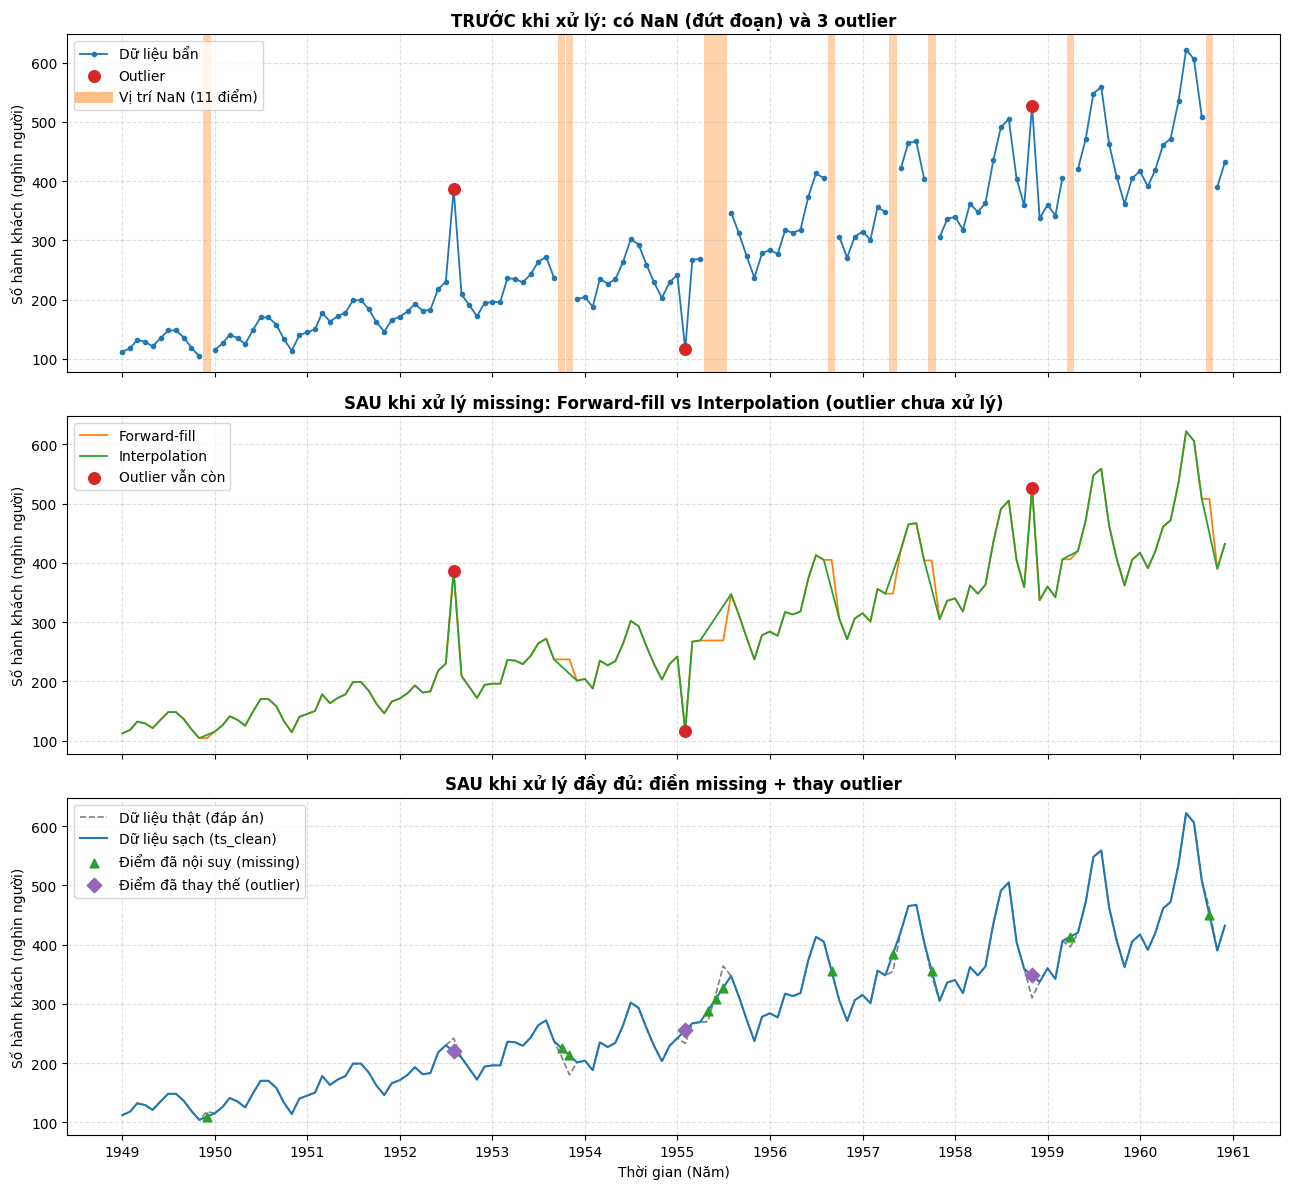

In [23]:
# Vẽ trước và sau khi xử lý
fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True, sharey=True)

# --- TRƯỚC khi xử lý ---
axes[0].plot(ts_dirty.index, ts_dirty.values, color="#1f77b4", linewidth=1.3, marker="o", markersize=3, label="Dữ liệu bẩn")
for d in missing_dates:
    axes[0].axvspan(d - pd.Timedelta(days=15), d + pd.Timedelta(days=15), color="#ff7f0e", alpha=0.35, linewidth=0)
axes[0].scatter(outlier_dates, ts_dirty[outlier_dates], color="#d62728", s=70, zorder=5, label="Outlier")
axes[0].plot([], [], color="#ff7f0e", alpha=0.5, linewidth=8, label="Vị trí NaN (11 điểm)")
axes[0].set_title("TRƯỚC khi xử lý: có NaN (đứt đoạn) và 3 outlier", fontsize=12, fontweight="bold")
axes[0].legend(loc="upper left")

# --- SAU khi chỉ điền missing ---
axes[1].plot(ts_ffill.index, ts_ffill.values, color="#ff7f0e", linewidth=1.3, label="Forward-fill")
axes[1].plot(ts_interp.index, ts_interp.values, color="#2ca02c", linewidth=1.3, label="Interpolation")
axes[1].scatter(outlier_dates, ts_interp[outlier_dates], color="#d62728", s=70, zorder=5, label="Outlier vẫn còn")
axes[1].set_title("SAU khi xử lý missing: Forward-fill vs Interpolation (outlier chưa xử lý)", fontsize=12, fontweight="bold")
axes[1].legend(loc="upper left")

# --- SAU khi xử lý cả missing và outlier ---
axes[2].plot(ts_true.index, ts_true.values, color="gray", linestyle="--", linewidth=1.2, label="Dữ liệu thật (đáp án)")
axes[2].plot(ts_clean.index, ts_clean.values, color="#1f77b4", linewidth=1.5, label="Dữ liệu sạch (ts_clean)")
axes[2].scatter(missing_dates, ts_clean[missing_dates], color="#2ca02c", marker="^", s=40, zorder=5, label="Điểm đã nội suy (missing)")
axes[2].scatter(outlier_dates, ts_clean[outlier_dates], color="#9467bd", marker="D", s=55, zorder=5, label="Điểm đã thay thế (outlier)")
axes[2].set_title("SAU khi xử lý đầy đủ: điền missing + thay outlier", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Thời gian (Năm)")
axes[2].legend(loc="upper left")
axes[2].xaxis.set_major_locator(mdates.YearLocator())
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

for ax in axes:
    ax.set_ylabel("Số hành khách (nghìn người)")
    ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

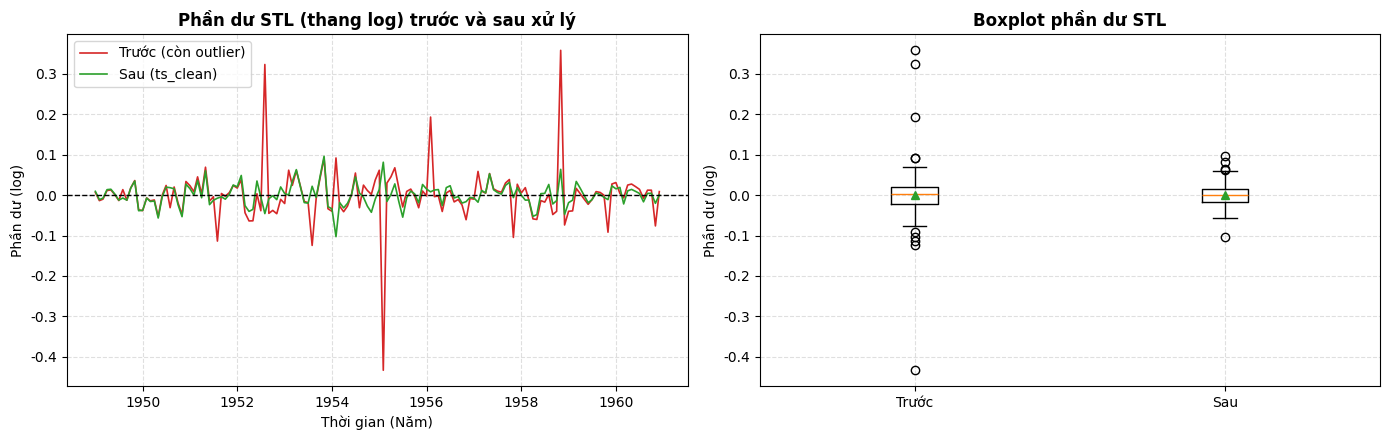

Độ lệch chuẩn phần dư: trước = 0.0675 | sau = 0.0275
Số điểm |z|>3 trên phần dư: trước = 3 | sau = 2


In [24]:
# Phần dư STL và phân phối trước/sau xử lý
resid_before = log_resid
resid_after = STL(np.log(ts_clean), period=12, robust=False).fit().resid

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(resid_before.index, resid_before.values, color="#d62728", linewidth=1.2, label="Trước (còn outlier)")
axes[0].plot(resid_after.index, resid_after.values, color="#2ca02c", linewidth=1.2, label="Sau (ts_clean)")
axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0].set_title("Phần dư STL (thang log) trước và sau xử lý", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Thời gian (Năm)")
axes[0].set_ylabel("Phần dư (log)")
axes[0].legend()

axes[1].boxplot([resid_before.values, resid_after.values], tick_labels=["Trước", "Sau"], showmeans=True)
axes[1].set_title("Boxplot phần dư STL", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Phần dư (log)")
for ax in axes:
    ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

print(f"Độ lệch chuẩn phần dư: trước = {resid_before.std():.4f} | sau = {resid_after.std():.4f}")
print(f"Số điểm |z|>3 trên phần dư: trước = {int(out_z_res.sum())} | sau = {int((((resid_after - resid_after.mean()) / resid_after.std()).abs() > 3).sum())}")

***KẾT LUẬN VẤN ĐỀ CHẤT LƯỢNG DỮ LIỆU***

**1. Kiểm tra missing**
- Dữ liệu AirPassengers gốc **không có NaN**. Sau khi giả lập, `isna().sum()` báo **11/144 giá trị thiếu (7,64%)**, gồm 1 khoảng thiếu liên tiếp 3 tháng (05–07/1955), 1 khoảng 2 tháng (10–11/1953) và 6 điểm đơn lẻ.
- Chỉ số thời gian vẫn đủ 144 mốc (không mất dòng), NaN chỉ nằm ở cột giá trị.

**2. Forward-fill và Interpolation**
- Với chuỗi **tăng dần và có mùa vụ**, Forward-fill cho sai số lớn hơn nhiều: **MAE 37,3 / RMSE 46,1 / MAPE 12,9%**, so với Interpolation: **MAE 16,7 / RMSE 20,1 / MAPE 6,3%** (giảm hơn một nửa sai số).
- Khoảng thiếu 3 tháng cho thấy rõ sự khác biệt: Forward-fill giữ nguyên 269 suốt 3 tháng (lệch tới -95 ở 07/1955), Interpolation bám xu hướng hơn (lệch -37).
- **Hạn chế của Interpolation tuyến tính:** nó nối thẳng hai đầu nên làm phẳng đỉnh/đáy mùa vụ (ví dụ 11/1953: điền 212,9, thật 180). Với khoảng thiếu dài trên chuỗi mùa vụ mạnh, nên dùng nội suy có tính mùa vụ (ví dụ nội suy trên phần STL).
- Ngoài ra Forward-fill không xử lý được NaN ở đầu chuỗi, còn `interpolate` mặc định không điền NaN ở hai đầu mút.

**3. Phát hiện outlier**

| Phương pháp | Bắt đúng (/3) | Báo nhầm | Nhận xét |
|---|---|---|---|
| Rolling mean/std (|z|>3) | 2 | 0 | Bỏ sót 11/1958 (z = 2,25) vì rolling std ở cuối chuỗi đã lớn do xu hướng và mùa vụ |
| Z-score / IQR trên chuỗi gốc | 0 | 0 | Ngưỡng toàn cục bị xu hướng làm méo, không bắt được điểm nào |
| Z-score phần dư STL (|z|>3) | **3** | **0** | Chính xác nhất (|z| từ 4,8 đến 6,4) |
| IQR 1.5x phần dư STL | 3 | 7 | Quá nhạy, đánh dấu cả các tháng mùa vụ bình thường |
| IQR 3x phần dư STL | 3 | 1 | Cải thiện rõ khi nới hàng rào |

- Bài học chính: **phải loại xu hướng và mùa vụ trước** (phần dư STL trên thang log) rồi mới dùng Z-score/IQR. Rolling mean/variance dễ dùng nhưng phụ thuộc cửa sổ và kém ổn định khi phương sai tăng theo thời gian.

**4. Kết quả sau xử lý**
- Thay 3 outlier (Z-score phần dư STL) bằng NaN rồi nội suy. Sai số tại 14 điểm bị làm hỏng giảm từ **MAE 47,3 / RMSE 78,5** (chỉ điền missing) xuống **MAE 19,0 / RMSE 22,1**. Độ lệch chuẩn phần dư STL giảm từ 0,0675 xuống 0,0275.
- Sau xử lý vẫn còn 2 điểm |z|>3 trên phần dư mới: **02/1954** là điểm lệch nhẹ vốn có của dữ liệu gốc (đã nêu ở Bài 5), còn **11/1953** là hệ quả của việc nội suy tuyến tính làm phẳng đáy mùa vụ. Hai điểm này không phải lỗi thật nên không cần xử lý thêm.

**5. Lưu ý**
Phương pháp xử lý cần phù hợp với đặc điểm chuỗi: đây là chuỗi có xu hướng và mùa vụ nhân, nên log + STL là bước đệm cần thiết. Việc tự chèn lỗi giúp đánh giá khách quan, còn với dữ liệu thực cần kiểm tra kỹ nguyên nhân của điểm bất thường (lỗi nhập liệu hay sự kiện thật) trước khi thay thế.

## 6. Trực quan hóa dữ liệu chuỗi thời gian (Bài tập 5)

***Mục tiêu bài thực hành:***
1. **Line chart:** Vẽ toàn bộ chuỗi thời gian **AirPassengers** (144 quan sát, 01/1949 – 12/1960).
2. **Rolling statistics:** Vẽ **rolling mean** và **rolling std** với cửa sổ `window = 12`.
3. **Seasonal plot:** Vẽ biểu đồ mùa vụ theo tháng (mỗi năm một đường).
4. **Heatmap seasonality:** Vẽ heatmap **tháng × năm**.
5. **Kết luận:** Xu hướng chung, các mùa vụ nổi bật và các điểm bất thường (nếu có).

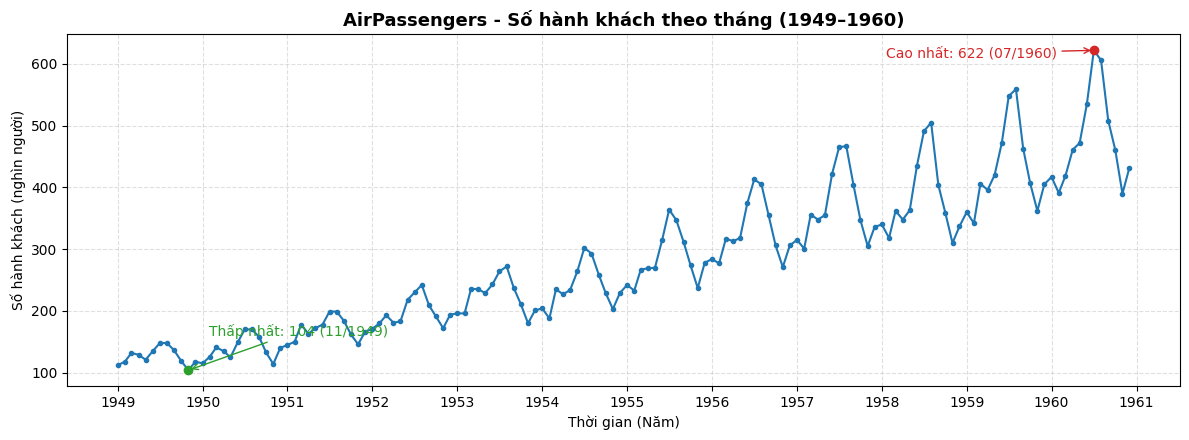

In [25]:
# Vẽ line chart toàn bộ chuỗi

fig, ax = plt.subplots(figsize=(12, 4.5))

ax.plot(ts.index, ts.values, color="#1f77b4", linewidth=1.5, marker="o", markersize=3)

# Đánh dấu giá trị lớn nhất và nhỏ nhất
t_max, v_max = ts.idxmax(), ts.max()
t_min, v_min = ts.idxmin(), ts.min()
ax.scatter([t_max], [v_max], color="#d62728", zorder=5)
ax.annotate(f"Cao nhất: {v_max} ({t_max:%m/%Y})", xy=(t_max, v_max),
            xytext=(-150, -5), textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color="#d62728"), color="#d62728")
ax.scatter([t_min], [v_min], color="#2ca02c", zorder=5)
ax.annotate(f"Thấp nhất: {v_min} ({t_min:%m/%Y})", xy=(t_min, v_min),
            xytext=(15, 25), textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color="#2ca02c"), color="#2ca02c")

ax.set_title("AirPassengers - Số hành khách theo tháng (1949–1960)", fontsize=13, fontweight="bold")
ax.set_xlabel("Thời gian (Năm)")
ax.set_ylabel("Số hành khách (nghìn người)")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


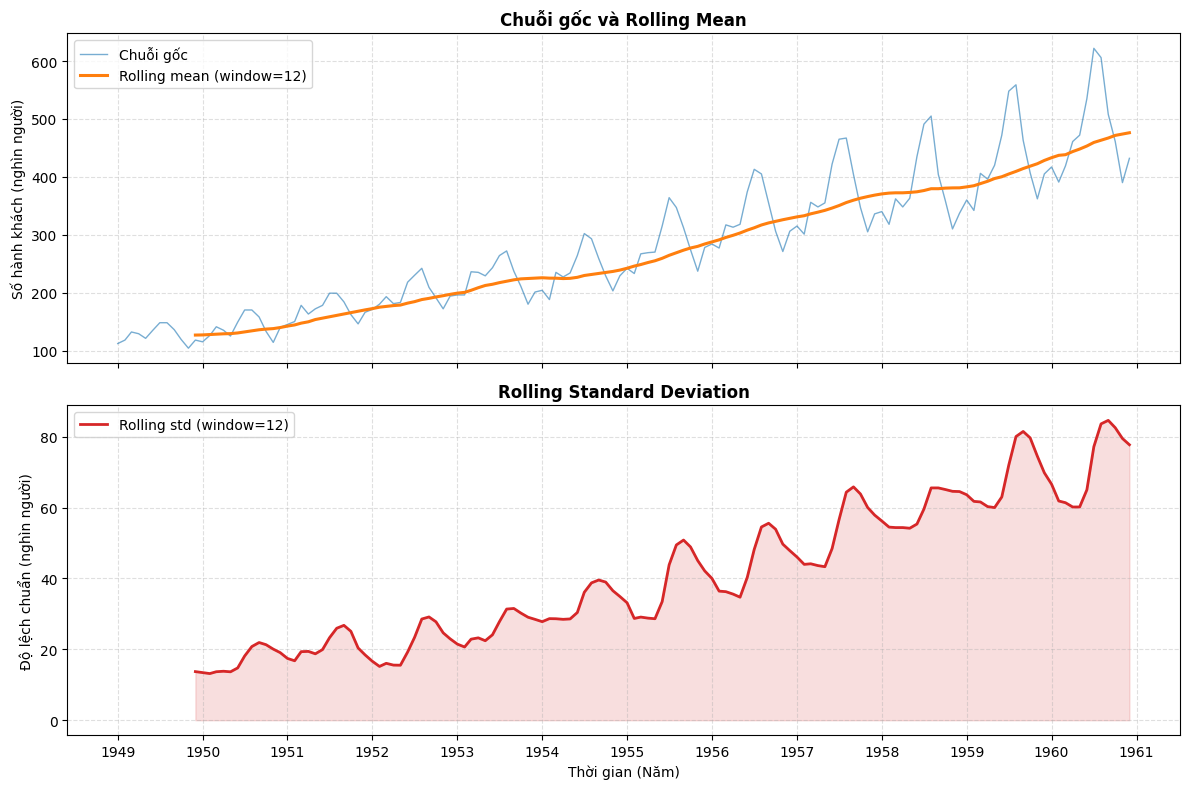

11 quan sát đầu tiên không có giá trị rolling (chưa đủ cửa sổ).
Rolling mean: 126.7 (12/1949) -> 476.2 (12/1960)
Rolling std : 13.7 (12/1949) -> 77.7 (12/1960)
Hệ số tương quan giữa rolling mean và rolling std: 0.959
Hệ số biến thiên (std/mean): trung bình 0.142, nhỏ nhất 0.087, lớn nhất 0.197


In [26]:
# Tính và vẽ rolling mean, rolling std với window = 12

WINDOW = 12
roll_mean = ts.rolling(window=WINDOW).mean()
roll_std = ts.rolling(window=WINDOW).std()

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Biểu đồ 1: chuỗi gốc và rolling mean
axes[0].plot(ts.index, ts.values, color="#1f77b4", linewidth=1.0, alpha=0.6, label="Chuỗi gốc")
axes[0].plot(roll_mean.index, roll_mean.values, color="#ff7f0e", linewidth=2.2,
             label=f"Rolling mean (window={WINDOW})")
axes[0].set_title("Chuỗi gốc và Rolling Mean", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Số hành khách (nghìn người)")
axes[0].legend(loc="upper left")

# Biểu đồ 2: rolling std
axes[1].plot(roll_std.index, roll_std.values, color="#d62728", linewidth=2.0,
             label=f"Rolling std (window={WINDOW})")
axes[1].fill_between(roll_std.index, roll_std.values, alpha=0.15, color="#d62728")
axes[1].set_title("Rolling Standard Deviation", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Thời gian (Năm)")
axes[1].set_ylabel("Độ lệch chuẩn (nghìn người)")
axes[1].legend(loc="upper left")
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

for ax in axes:
    ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# Thống kê tóm tắt
valid = pd.DataFrame({"mean": roll_mean, "std": roll_std}).dropna()
cv = valid["std"] / valid["mean"]
print(f"{WINDOW - 1} quan sát đầu tiên không có giá trị rolling (chưa đủ cửa sổ).")
print(f"Rolling mean: {valid['mean'].iloc[0]:.1f} ({valid.index[0]:%m/%Y}) -> {valid['mean'].iloc[-1]:.1f} ({valid.index[-1]:%m/%Y})")
print(f"Rolling std : {valid['std'].iloc[0]:.1f} ({valid.index[0]:%m/%Y}) -> {valid['std'].iloc[-1]:.1f} ({valid.index[-1]:%m/%Y})")
print(f"Hệ số tương quan giữa rolling mean và rolling std: {valid['mean'].corr(valid['std']):.3f}")
print(f"Hệ số biến thiên (std/mean): trung bình {cv.mean():.3f}, nhỏ nhất {cv.min():.3f}, lớn nhất {cv.max():.3f}")


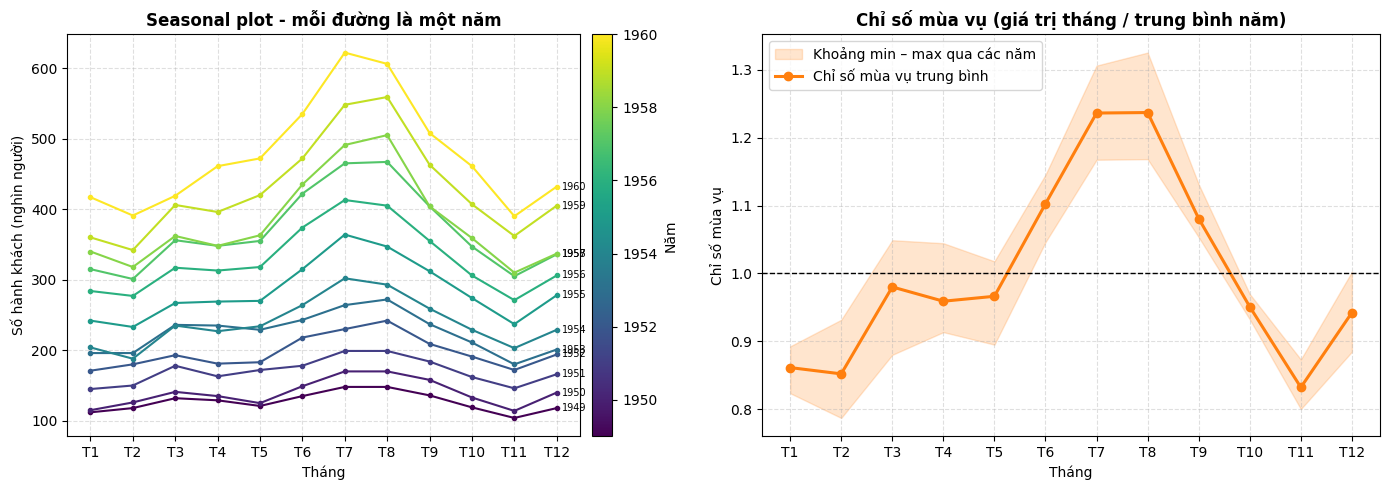

Chỉ số mùa vụ trung bình theo tháng:


Month,T1,T2,T3,T4,T5,T6,T7,T8,T9,T10,T11,T12
Chỉ số mùa vụ,0.861,0.852,0.98,0.959,0.966,1.103,1.236,1.237,1.081,0.951,0.832,0.942



Số năm có đỉnh ở từng tháng: {7: 7, 8: 5}
Số năm có đáy ở từng tháng : {1: 2, 2: 4, 11: 6}


In [27]:
# Chuẩn bị bảng tháng × năm và vẽ seasonal plot

table = (
    ts.to_frame("Passengers")
      .assign(Year=ts.index.year, Month=ts.index.month)
      .pivot(index="Month", columns="Year", values="Passengers")
)
month_labels = [f"T{m}" for m in range(1, 13)]
years = table.columns.tolist()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: mỗi năm một đường
cmap = cm.viridis
norm = Normalize(vmin=min(years), vmax=max(years))
for y in years:
    axes[0].plot(table.index, table[y], marker="o", markersize=3, linewidth=1.5, color=cmap(norm(y)))
    axes[0].annotate(str(y), xy=(12, table.loc[12, y]), xytext=(4, 0),
                     textcoords="offset points", fontsize=7, va="center")
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
fig.colorbar(sm, ax=axes[0], label="Năm", pad=0.02)
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(month_labels)
axes[0].set_title("Seasonal plot - mỗi đường là một năm", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Tháng")
axes[0].set_ylabel("Số hành khách (nghìn người)")
axes[0].grid(True, linestyle="--", alpha=0.4)

# Biểu đồ 2: chỉ số mùa vụ (giá trị tháng / trung bình năm) để loại bỏ ảnh hưởng của xu hướng
seasonal_ratio = table / table.mean(axis=0)
si_mean = seasonal_ratio.mean(axis=1)
axes[1].fill_between(table.index, seasonal_ratio.min(axis=1), seasonal_ratio.max(axis=1),
                     alpha=0.2, color="#ff7f0e", label="Khoảng min – max qua các năm")
axes[1].plot(table.index, si_mean, color="#ff7f0e", marker="o", linewidth=2.2, label="Chỉ số mùa vụ trung bình")
axes[1].axhline(1, color="black", linestyle="--", linewidth=1)
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(month_labels)
axes[1].set_title("Chỉ số mùa vụ (giá trị tháng / trung bình năm)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Tháng")
axes[1].set_ylabel("Chỉ số mùa vụ")
axes[1].legend(loc="upper left")
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

print("Chỉ số mùa vụ trung bình theo tháng:")
display(si_mean.round(3).rename("Chỉ số mùa vụ").to_frame().T.rename(columns=dict(zip(range(1, 13), month_labels))))

peak = table.idxmax(axis=0)
trough = table.idxmin(axis=0)
print("\nSố năm có đỉnh ở từng tháng:", peak.value_counts().sort_index().to_dict())
print("Số năm có đáy ở từng tháng :", trough.value_counts().sort_index().to_dict())


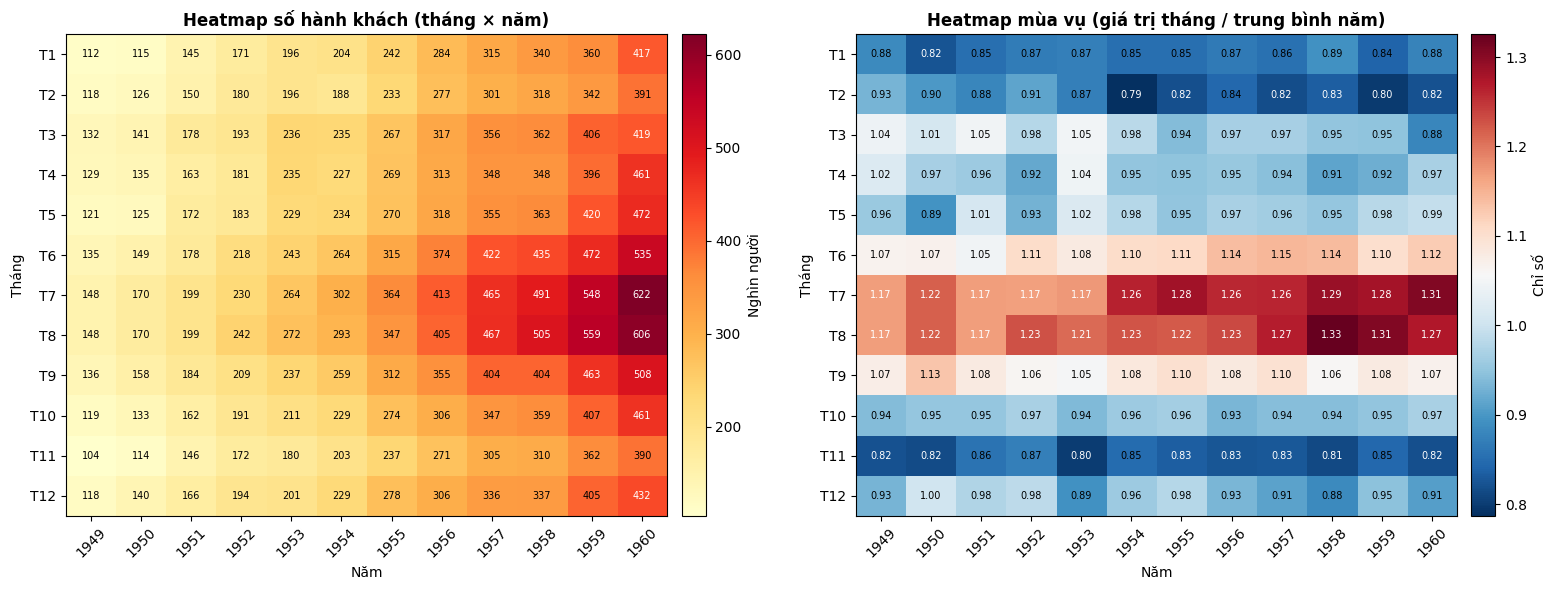

In [28]:
# Heatmap tháng × năm (giá trị gốc và giá trị đã chuẩn hóa theo trung bình năm)

def ve_heatmap(ax, data, title, cmap_name, fmt, cbar_label, diverging=False):
    im = ax.imshow(data.values, aspect="auto", cmap=cmap_name)
    ax.set_xticks(range(len(data.columns)))
    ax.set_xticklabels(data.columns, rotation=45)
    ax.set_yticks(range(len(data.index)))
    ax.set_yticklabels(month_labels)
    ax.set_xlabel("Năm")
    ax.set_ylabel("Tháng")
    ax.set_title(title, fontsize=12, fontweight="bold")
    # Ghi giá trị lên từng ô, đổi màu chữ theo độ đậm của ô
    vmin, vmax = np.nanmin(data.values), np.nanmax(data.values)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            val = data.values[i, j]
            if diverging:
                # Thang phân kỳ: ô đậm ở cả hai đầu (xa mức 1) dùng chữ trắng
                dark = abs(val - 1) / max(abs(vmin - 1), abs(vmax - 1)) > 0.5
            else:
                dark = (val - vmin) / (vmax - vmin) > 0.6
            ax.text(j, i, format(val, fmt), ha="center", va="center", fontsize=7,
                    color="white" if dark else "black")
    plt.colorbar(im, ax=ax, label=cbar_label, pad=0.02)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ve_heatmap(axes[0], table, "Heatmap số hành khách (tháng × năm)", "YlOrRd", ".0f", "Nghìn người")
ve_heatmap(axes[1], seasonal_ratio, "Heatmap mùa vụ (giá trị tháng / trung bình năm)", "RdBu_r", ".2f", "Chỉ số", diverging=True)

plt.tight_layout()
plt.show()


In [29]:
# Tổng hợp số liệu để rút ra kết luận

# (a) Xu hướng: trung bình theo năm và tốc độ tăng
annual = ts.groupby(ts.index.year).agg(["mean", "std", "min", "max"]).round(1)
annual["Tăng so với năm trước (%)"] = (annual["mean"].pct_change() * 100).round(1)
print("(a) Thống kê theo năm:")
display(annual)
cagr = (annual["mean"].iloc[-1] / annual["mean"].iloc[0]) ** (1 / (len(annual) - 1)) - 1
print(f"Trung bình năm tăng {annual['mean'].iloc[-1] / annual['mean'].iloc[0]:.2f} lần, tốc độ tăng bình quân ~{cagr * 100:.1f}%/năm")

# (b) Biên độ mùa vụ: chênh lệch giữa tháng 7 và tháng 11 (đỉnh và đáy điển hình)
gap = (table.loc[7] - table.loc[11])
ratio = (table.loc[7] / table.loc[11])
print("\n(b) Chênh lệch tuyệt đối T7 - T11 từng năm (nghìn người):")
print(gap.to_dict())
print(f"Tỷ lệ T7/T11: {ratio.iloc[0]:.2f} (1949) -> {ratio.iloc[-1]:.2f} (1960)")

# (c) Bất thường: phần dư STL trên thang log, đánh dấu |z| > 3
log_resid = STL(np.log(ts), period=12, robust=True).fit().resid
z = (log_resid - log_resid.mean()) / log_resid.std()
print("\n(c) Các tháng có phần dư STL (thang log) lệch quá 3 độ lệch chuẩn:")
display(pd.DataFrame({"Giá trị": ts[z.abs() > 3], "z-score": z[z.abs() > 3].round(2)}))

# (d) Biến động theo tháng lớn nhất
mom = ts.pct_change() * 100
print("(d) 3 tháng giảm mạnh nhất so với tháng trước (%):")
print(mom.nsmallest(3).round(1).to_string())


(a) Thống kê theo năm:


,mean,std,min,max,Tăng so với năm trước (%)
1949,126.7,13.7,104,148,NaN
1950,139.7,19.1,114,170,10.3
1951,170.2,18.4,145,199,21.8
1952,197.0,23.0,171,242,15.7
1953,225.0,28.5,180,272,14.2
1954,238.9,34.9,188,302,6.2
1955,284.0,42.1,233,364,18.9
1956,328.2,47.9,271,413,15.6
1957,368.4,57.9,301,467,12.2
1958,381.0,64.5,310,505,3.4


Trung bình năm tăng 3.76 lần, tốc độ tăng bình quân ~12.8%/năm

(b) Chênh lệch tuyệt đối T7 - T11 từng năm (nghìn người):
{1949: 44, 1950: 56, 1951: 53, 1952: 58, 1953: 84, 1954: 99, 1955: 127, 1956: 142, 1957: 160, 1958: 181, 1959: 186, 1960: 232}
Tỷ lệ T7/T11: 1.42 (1949) -> 1.59 (1960)

(c) Các tháng có phần dư STL (thang log) lệch quá 3 độ lệch chuẩn:


,Giá trị,z-score
1951-05-01,172,3.28
1953-03-01,236,3.05
1953-04-01,235,4.35
1953-05-01,229,3.32
1954-02-01,188,-4.28


(d) 3 tháng giảm mạnh nhất so với tháng trước (%):
1958-09-01   -20.0
1959-09-01   -17.2
1960-09-01   -16.2


***KẾT LUẬN TRỰC QUAN HÓA DỮ LIỆU CHUỖI THỜI GIAN***

**1. Xu hướng chung (Trend)**
- Lượng hành khách có xu hướng **tăng mạnh và liên tục** trong cả giai đoạn 1949–1960: trung bình năm tăng từ khoảng **127 nghìn** (1949) lên khoảng **476 nghìn** (1960), gấp khoảng 3,8 lần, tương ứng tốc độ tăng bình quân khoảng 12,8%/năm.
- Rolling mean (window=12) đi lên gần như đều, không có giai đoạn suy giảm kéo dài. Tăng trưởng chậm lại rõ nhất ở năm 1954 (+6,2%) và 1958 (+3,4%).
- Rolling std cũng tăng từ khoảng 14 lên khoảng 78 và có tương quan rất cao với rolling mean (≈ 0,96): chuỗi **không dừng** cả về trung bình lẫn phương sai, độ biến động tăng theo quy mô.

**2. Mùa vụ nổi bật (Seasonality)**
- Chu kỳ **12 tháng** lặp lại ổn định ở mọi năm: đỉnh vào **tháng 7–8** (chỉ số mùa vụ ≈ 1,24, tức cao hơn trung bình năm khoảng 24%; tháng 7 là đỉnh ở 7/12 năm, tháng 8 ở 5/12 năm).
- Đáy rơi vào **tháng 11** (chỉ số ≈ 0,83), kế đến là **tháng 2 và tháng 1** (≈ 0,85–0,86). Tháng 6 và tháng 9 là hai tháng "vai" của mùa cao điểm; tháng 12 hồi nhẹ so với tháng 11.
- Biên độ mùa vụ **tăng dần theo thời gian**: chênh lệch T7 – T11 tăng từ 44 nghìn (1949) lên 232 nghìn (1960), trong khi tỷ lệ T7/T11 chỉ dao động trong khoảng 1,3–1,6. Đây là mùa vụ dạng **nhân (multiplicative)**, phù hợp với kết quả ở Bài tập 3. Heatmap chuẩn hóa cho thấy cùng một dải màu đậm ở tháng 6–9 và dải màu nhạt ở tháng 11–2 lặp lại ở mọi năm.

**3. Bất thường (Anomaly)**
- Không có outlier cực đoan: các điểm cao nhất (T7/1960 = 622) và thấp nhất (T11/1949 = 104) đều phù hợp với xu hướng và mùa vụ.
- Có một số điểm lệch nhẹ so với quy luật chung (phần dư STL trên thang log vượt 3 độ lệch chuẩn): **tháng 5/1951** và **mùa xuân 1953** (tháng 3–5) cao hơn mức mùa vụ thông thường; **tháng 2/1954** (188) thấp hơn cùng kỳ năm trước (196), là mức giảm so với cùng kỳ rõ nhất trong chuỗi.
- **Năm 1958** tăng trưởng chậm (+3,4%): các tháng 4 và 9/1958 bằng đúng mức cùng kỳ 1957 (348 và 404). Mức giảm tháng 9 so với tháng 8 (từ khoảng -7% đến -20%, mức giảm sâu hơn ở các năm về sau) là quy luật mùa vụ lặp lại ở mọi năm, không phải bất thường riêng của 1958.
- Biên độ dao động ngày càng lớn ở cuối chuỗi (rolling std tăng) là hệ quả của quy mô tăng, không phải dấu hiệu dữ liệu lỗi.



## 7. Kết luận Dữ liệu có phù hợp để dự báo không?

**Kết luận:** Tập dữ liệu `AirPassengers` **RẤT PHÙ HỢP** để xây dựng các mô hình dự báo học máy hoặc chuỗi thời gian.

**Lý do:**
1. **Cấu trúc dữ liệu mạnh mẽ:** Dữ liệu mang tính quy luật cực kỳ cao với Xu hướng (Trend) rõ ràng và Chu kỳ mùa vụ (Seasonality) lặp lại đều đặn. ACF và PACF cũng cho thấy sự tự tương quan mạnh mẽ, tức là quá khứ chứa rất nhiều thông tin để dự đoán tương lai.
2. **Chất lượng dữ liệu tốt:** Phần dư (Residual) sau khi phân rã là White Noise, chứng tỏ mô hình có thể bóc tách 100% cấu trúc dữ liệu. Hơn nữa, dữ liệu gốc không bị nhiễu (noise) hay lỗi missing nghiêm trọng.
3. **Đề xuất tiền xử lý:** Vì chuỗi mang tính "Không dừng" (Non-stationary), trước khi đưa vào các mô hình dự báo như ARIMA hay mạng nơ-ron (LSTM), cần thực hiện biến đổi Logarit (để ổn định phương sai) và lấy sai phân (Differencing) để loại bỏ xu hướng.